# What should a Hong Kong host charge? A data-driven pricing benchmark for short- and mid-term rentals
**IS3240 Advanced Business Programming in Python – Group Project (code notebook)**

---
## 1. The business problem

Hong Kong has one of the most expensive and most regulated accommodation markets in the world. Operators of Airbnb-type
listings – from individual hosts renting a spare room to professional property managers running dozens of flats – face
the same recurring decision: **"what nightly price should I put on this listing?"**

* **Too high** and the listing sits empty; **too low** and the operator gives revenue away on every night booked.
* Pricing is hard because the market is *two markets in one*: Hong Kong law restricts renting out residential premises for
  fewer than 28 consecutive days without a licence, so a large share of listings are actually **monthly rentals** whose
  nightly price is a fraction of a tourist stay.
* Price depends on many things at once – location, transit access, size, amenities, who the host is – and hosts usually
  fall back on eyeballing a few "comparable" listings.

**Our objective:** use machine learning in Python to build a *pricing benchmark* that (i) predicts a fair asking price and a
plausible price band for a listing from information available **before the first guest arrives**, (ii) explains what drives
price and by how much, (iii) flags listings that are priced far from the benchmark, and (iv) tests whether being priced above
the benchmark is associated with weaker guest demand.

**Who uses it?** *Hosts and property managers* (set / review prices, decide which upgrades are worth it), *investors* (which
segments and districts are attractive) and, indirectly, *platforms and policy makers* (how big the monthly-rental segment is).

## 2. Analytical roadmap (follows the "story-telling" framework from Week 5)
| Step | Question | Notebook section |
|---|---|---|
| Problem & motivation | Why does price benchmarking matter here? | 1 |
| Data | What do we have, how good is it, what did we remove and why? | 2 – 3 |
| Market understanding | What does the market look like (stay regimes, geography)? | 4 – 5 |
| Useful factors | What factors might explain price, why, and how are they computed? | 6 – 7 |
| Market segments | Which natural segments exist? (unsupervised learning, KMeans + PCA) | 8 |
| Suitable models | Which models, evaluated how, and why? (supervised learning) | 9 – 11 |
| Excellent performance | How good is the benchmark for a real user? | 11 |
| Insight | What drives price? Who is over/under-priced? Does it cost demand? | 12 – 14 |
| Action | How would a host use it? What should they do? | 15 – 16 |

**Data:** Inside Airbnb – Hong Kong (listings detailed file, scraped 25 Sep 2026; reviews file), plus **MTR station
locations from OpenStreetMap** (via the Overpass API, a web-data-collection step as in Week 4).

**How to run:** place the three files in `data/` and run all cells (`Kernel → Restart & Run All`). The MTR stations are
cached in `data/mtr_stations.csv`, so the notebook also runs offline. Every figure and number quoted in the report is
produced here and saved to `outputs/`.

## 2. Setup and data loading

In [1]:
import os, warnings, json, re, glob, time, textwrap
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))   # silences a harmless joblib warning on Windows
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import requests
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import BallTree
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA, OUT = ROOT / "data", ROOT / "outputs"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

RESULTS = {}          # every number quoted in the report is stored here and written to outputs/results.json

def save_results():
    def _clean(o):
        if isinstance(o, (np.integer,)): return int(o)
        if isinstance(o, (np.floating,)): return float(o)
        if isinstance(o, (np.ndarray,)): return o.tolist()
        if isinstance(o, (pd.Timestamp,)): return str(o.date())
        return str(o)
    (OUT / "results.json").write_text(json.dumps(RESULTS, indent=2, default=_clean), encoding="utf8")

# ---- visual identity: validated colour-blind-safe categorical palette, one-hue sequential ramp ----
PAL = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
           green="#008300", violet="#6250d6", red="#e34948",
           ink="#0b0b0b", ink2="#52514e", muted="#898781", grid="#e1e0d9", axis="#c3c2b7", surface="#fcfcfb")
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CAT = [PAL[c] for c in ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": PAL["surface"], "savefig.facecolor": "white",
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 8, "text.color": PAL["ink2"],
    "axes.titlesize": 8.8, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": PAL["ink"],
    "axes.labelsize": 8, "axes.labelcolor": PAL["ink2"], "axes.edgecolor": PAL["axis"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": PAL["grid"],
    "grid.linewidth": 0.6, "axes.axisbelow": True, "xtick.color": PAL["muted"], "ytick.color": PAL["muted"],
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.frameon": False, "legend.fontsize": 7.5,
    "figure.dpi": 110, "savefig.dpi": 220,
})

def savefig(name, fig=None):
    fig = fig or plt.gcf()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=220)
    plt.show()

def pct(x, d=0): return f"{100*x:.{d}f}%"

In [2]:
f_det = sorted(glob.glob(str(DATA / "listings*.csv.gz")))[0]          # detailed listings file (any '(1)' suffix is fine)
L = pd.read_csv(f_det)
S = pd.read_csv(DATA / "listings.csv")                                   # summary file (quick checks only)
R = pd.read_csv(DATA / "reviews.csv.gz")
SCRAPE_DATE = pd.to_datetime(L.last_scraped.iloc[0])

L["price_hkd"] = pd.to_numeric(L.price.astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
for c in ["first_review", "last_review"]:
    L[c] = pd.to_datetime(L[c])
R["date"] = pd.to_datetime(R["date"])

empty_cols = L.columns[L.isna().all()].tolist()
print(f"Detailed listings : {L.shape[0]:,} rows x {L.shape[1]} columns   (scraped {SCRAPE_DATE.date()})")
print(f"Summary listings  : {S.shape[0]:,} rows x {S.shape[1]} columns")
print(f"Reviews           : {R.shape[0]:,} rows, {R.listing_id.nunique():,} listings, {R.date.min().date()} -> {R.date.max().date()}")
print(f"Completely empty columns in the detailed file: {len(empty_cols)}  e.g. {empty_cols[:8]}")
print("Same listing ids in summary and detailed file:", set(S.id) == set(L.id))
print(f"Summary price == detailed price for only {pct((S.set_index('id').price.round(2) == L.set_index('id').price_hkd.round(2))[L.set_index('id').price_hkd.notna()].mean())} of listings -> we use the detailed file only")

RESULTS["data"] = dict(
    n_listings=len(L), n_columns=L.shape[1], n_reviews=len(R), n_listings_with_reviews=int(R.listing_id.nunique()),
    scrape_date=str(SCRAPE_DATE.date()), review_first=str(R.date.min().date()), review_last=str(R.date.max().date()),
    n_empty_columns=len(empty_cols), license_missing=bool(L.license.isna().all()),
    price_missing_pct=float(L.price_hkd.isna().mean()),
)
display_cols = ["price_hkd", "minimum_nights", "bedrooms", "beds", "review_scores_rating", "amenities", "description"]
pd.DataFrame({"missing_%": (L[display_cols].isna().mean() * 100).round(1)}).T

Detailed listings : 6,614 rows x 91 columns   (scraped 2026-09-25)
Summary listings  : 6,614 rows x 19 columns
Reviews           : 122,715 rows, 3,731 listings, 2011-02-26 -> 2026-09-24
Completely empty columns in the detailed file: 15  e.g. ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count']
Same listing ids in summary and detailed file: True
Summary price == detailed price for only 39% of listings -> we use the detailed file only


,price_hkd,minimum_nights,bedrooms,beds,review_scores_rating,amenities,description
missing_%,15.3,0.3,0.3,2.1,43.6,0.0,0.4


**What the audit tells us (and what we decide):**
* The `price` field is a **price quote for a specific stay** (the `price_quote_*` columns show check-in/out dates), and the
  length of that stay is almost identical to the host's `minimum_nights`. A "price per night" is therefore *not comparable*
  between a 1-night and a 30-night stay – we must treat **stay length as a core factor**, not as noise.
* 15% of listings have **no price** – we check below that these are essentially listings that cannot be booked.
* The `license` column is entirely empty, so legal status **cannot** be analysed from these data (we do not pretend to).
* Several columns are 100% empty (host response rate, etc.) and are ignored.

## 3. Data preparation – every removal is a documented business decision

We only remove listings when we can argue that they do not belong to the question *"what is a fair asking price for a
bookable listing?"*. Each step is counted so the report can show how much data each decision costs.

In [3]:
steps = [("Listings in the detailed file", len(L), 0)]
d = L.copy()

# (1) No price. Check WHY before dropping: two thirds are un-bookable; the rest simply have no quote for the scrape window.
no_price = d.price_hkd.isna()
share_unbookable = (d.loc[no_price, "availability_365"] == 0).mean()
print(f"{no_price.sum():,} listings have no price; {pct(share_unbookable)} of them have availability_365 == 0 (cannot be booked in the next year)")
d = d[~no_price]
steps.append(("Drop listings without a price quote (mostly not bookable)", len(d), int(no_price.sum())))

# (2) Missing stay policy (cannot be assigned to a stay regime)
miss_min = d.minimum_nights.isna()
d = d[~miss_min]
steps.append(("Drop listings without minimum-nights policy", len(d), int(miss_min.sum())))

# (3) Implausible prices. Floor: a few HKD per night (e.g. a 0.73 HKD 'tent' with a 300-night quote) are data errors.
#     Cap: the 99.5th percentile. The model is meant to benchmark *typical* listings; a handful of 20k-150k HKD/night luxury or
#     erroneous listings would dominate squared-error metrics and are not the host's pricing problem.
PRICE_FLOOR = 50.0
PRICE_CAP = float(d.price_hkd.quantile(0.995))
bad = (d.price_hkd < PRICE_FLOOR) | (d.price_hkd > PRICE_CAP)
n_low, n_high = int((d.price_hkd < PRICE_FLOOR).sum()), int((d.price_hkd > PRICE_CAP).sum())
d = d[~bad]
steps.append((f"Drop implausible prices (< {PRICE_FLOOR:.0f} or > {PRICE_CAP:,.0f} HKD)", len(d), n_low + n_high))

df = d.copy()                      # NOTE: original index is kept so features computed on the full file can be aligned
df["regime"] = np.where(df.minimum_nights >= 28, "Long stay (28+ nights)", "Short stay (<28 nights)")
df["long_stay"] = (df.minimum_nights >= 28).astype(int)

clean_tbl = pd.DataFrame(steps, columns=["Step", "Listings left", "Removed"])
display(clean_tbl)
print(f"Final modelling sample: {len(df):,} listings from {df.host_id.nunique():,} hosts "
      f"({pct(len(df)/len(L))} of the file). Price range {df.price_hkd.min():.0f}-{df.price_hkd.max():,.0f} HKD, median {df.price_hkd.median():.0f}")
RESULTS["cleaning"] = dict(steps=[dict(step=a, left=int(b), removed=int(c)) for a, b, c in steps],
                           price_floor=PRICE_FLOOR, price_cap=PRICE_CAP, share_unbookable_among_missing=float(share_unbookable),
                           n_final=len(df), n_hosts=int(df.host_id.nunique()), median_price=float(df.price_hkd.median()),
                           mean_price=float(df.price_hkd.mean()))

1,011 listings have no price; 66% of them have availability_365 == 0 (cannot be booked in the next year)


,Step,Listings left,Removed
0,Listings in the detailed file,6614,0
1,Drop listings without a price quote (mostly no...,5603,1011
2,Drop listings without minimum-nights policy,5584,19
3,"Drop implausible prices (< 50 or > 7,534 HKD)",5555,29


Final modelling sample: 5,555 listings from 1,175 hosts (84% of the file). Price range 73-7,530 HKD, median 471


## 4. Understanding the market before modelling
Four facts shape everything that follows: where supply is concentrated, how many listings are really monthly rentals, how
much cheaper a long stay is per night, and how guest demand has evolved.

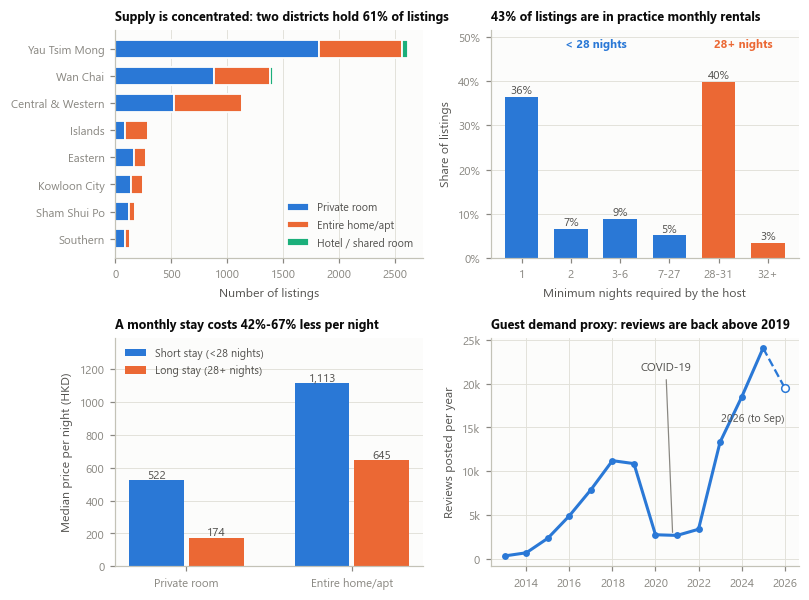

Hosts with 5+ listings own 73% of all listings (largest host: 344 listings)
Price skewness raw -> log: 3.1 -> 0.41


In [4]:
rt3 = L.room_type.where(L.room_type.isin(["Private room", "Entire home/apt"]), "Hotel / shared room")
ct = pd.crosstab(L.neighbourhood_cleansed, rt3)[["Private room", "Entire home/apt", "Hotel / shared room"]]
top8 = ct.sum(axis=1).sort_values(ascending=False).head(8).index
ct8 = ct.loc[top8].iloc[::-1]
top2_share = ct.sum(axis=1).sort_values(ascending=False).head(2).sum() / len(L)

bins = [0, 1, 2, 6, 27, 31, 10_000]
labels = ["1", "2", "3-6", "7-27", "28-31", "32+"]
mn = pd.cut(L.minimum_nights.dropna(), bins=bins, labels=labels)
mn_share = mn.value_counts(normalize=True).reindex(labels)
long_share = float((L.minimum_nights >= 28).mean())

med = df[df.room_type.isin(["Private room", "Entire home/apt"])].groupby(["room_type", "regime"]).price_hkd.median().unstack()
disc = 1 - med["Long stay (28+ nights)"] / med["Short stay (<28 nights)"]

yr = R.date.dt.year.value_counts().sort_index()
yr = yr[yr.index >= 2013]

fig, ax = plt.subplots(2, 2, figsize=(7.4, 5.5))
# (a) supply by district and room type
a = ax[0, 0]
left = np.zeros(len(ct8))
for col, c in zip(ct8.columns, [PAL["blue"], PAL["orange"], PAL["aqua"]]):
    a.barh(ct8.index, ct8[col], left=left, color=c, label=col, height=0.68, edgecolor=PAL["surface"], linewidth=1.2)
    left += ct8[col].values
a.set_title(f"Supply is concentrated: two districts hold {pct(top2_share)} of listings", fontsize=8.2)
a.set_xlabel("Number of listings"); a.grid(axis="y", visible=False)
a.legend(loc="lower right", fontsize=7)
# (b) minimum nights
b = ax[0, 1]
cols_b = [PAL["blue"]] * 4 + [PAL["orange"]] * 2
b.bar(labels, mn_share.values, color=cols_b, width=0.68)
for i, v in enumerate(mn_share.values):
    b.text(i, v + 0.008, pct(v), ha="center", fontsize=7.5, color=PAL["ink2"])
b.set_title(f"{pct(long_share)} of listings are in practice monthly rentals", fontsize=8.2)
b.set_xlabel("Minimum nights required by the host"); b.set_ylabel("Share of listings"); b.set_ylim(0, mn_share.max() * 1.3)
b.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); b.grid(axis="x", visible=False)
b.text(4.5, mn_share.max() * 1.2, "28+ nights", ha="center", color=PAL["orange"], fontsize=7.5, fontweight="bold")
b.text(1.5, mn_share.max() * 1.2, "< 28 nights", ha="center", color=PAL["blue"], fontsize=7.5, fontweight="bold")
# (c) median price by regime
c_ = ax[1, 0]
x = np.arange(2); w = 0.36
for j, (reg, col) in enumerate([("Short stay (<28 nights)", PAL["blue"]), ("Long stay (28+ nights)", PAL["orange"])]):
    vals = [med.loc[r, reg] for r in ["Private room", "Entire home/apt"]]
    c_.bar(x + (j - 0.5) * w, vals, w * 0.92, color=col, label=reg)
    for xi, v in zip(x + (j - 0.5) * w, vals):
        c_.text(xi, v + 12, f"{v:,.0f}", ha="center", fontsize=7.5, color=PAL["ink2"])
c_.set_xticks(x); c_.set_xticklabels(["Private room", "Entire home/apt"])
c_.set_ylabel("Median price per night (HKD)"); c_.legend(loc="upper left", fontsize=7); c_.grid(axis="x", visible=False)
c_.set_ylim(0, med.values.max() * 1.25)
c_.set_title(f"A monthly stay costs {pct(disc.min())}-{pct(disc.max())} less per night", fontsize=8.2)
# (d) reviews per year
d_ = ax[1, 1]
full = yr[yr.index < R.date.max().year]
d_.plot(full.index, full.values, color=PAL["blue"], lw=2, marker="o", ms=3.5)
d_.plot([full.index[-1], yr.index[-1]], [full.values[-1], yr.values[-1]], color=PAL["blue"], lw=1.5, ls="--")
d_.plot(yr.index[-1], yr.values[-1], marker="o", ms=5, mfc="white", mec=PAL["blue"])
d_.text(yr.index[-1], yr.values[-1] * 0.8, "2026 (to Sep)", ha="right", fontsize=7)
d_.annotate("COVID-19", xy=(2020.8, yr.loc[2021]), xytext=(2019.3, 21500), fontsize=7.5, color=PAL["ink2"],
            arrowprops=dict(arrowstyle="-", color=PAL["muted"], lw=0.8))
d_.set_title("Guest demand proxy: reviews are back above 2019", fontsize=8.2)
d_.set_ylabel("Reviews posted per year"); d_.set_xlabel("")
d_.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f"{v/1000:.0f}k" if v else "0"))
fig.tight_layout(h_pad=1.6, w_pad=1.4)
savefig("fig1_market_overview", fig)

host_pro = float((L.calculated_host_listings_count >= 5).mean())
RESULTS["eda"] = dict(
    top2_share=float(top2_share), top2_names=list(ct.sum(axis=1).sort_values(ascending=False).head(2).index),
    long_stay_share=long_share, private_room_share=float((L.room_type == "Private room").mean()),
    entire_share=float((L.room_type == "Entire home/apt").mean()),
    median_price={f"{r}|{g}": float(med.loc[r, g]) for r in med.index for g in med.columns},
    long_stay_discount={r: float(disc[r]) for r in disc.index},
    share_listings_from_hosts_5plus=host_pro, max_host_listings=int(L.calculated_host_listings_count.max()),
    n_hosts=int(L.host_id.nunique()), reviews_2019=int(yr.loc[2019]), reviews_2025=int(yr.loc[2025]),
    reviews_2021=int(yr.loc[2021]), superhost_share=float((L.host_is_superhost == "t").mean()),
    price_skew_raw=float(df.price_hkd.skew()), price_skew_log=float(np.log(df.price_hkd).skew()),
)
print(f"Hosts with 5+ listings own {pct(host_pro)} of all listings (largest host: {L.calculated_host_listings_count.max()} listings)")
print("Price skewness raw -> log:", round(df.price_hkd.skew(), 1), "->", round(np.log(df.price_hkd).skew(), 2))

**Business reading.**
* The market is **two markets**: short stays (typically tourists; the median nightly price is about 1.7× that of a monthly stay for whole homes and
  3× for private rooms) and monthly rentals. A single "average price" would be wrong for both; *stay policy is a first-class
  factor and the main segmentation of our analysis.*
* Supply is dominated by **private rooms in rental flats** and by two districts, so the benchmark must be especially good
  in those cells – and honest about thin cells (outlying districts).
* Professional hosts (5+ listings) own most of the supply. This is a **leakage risk** for machine learning: sister listings
  of one host in the same building look almost identical, so a random train/test split would overstate accuracy. We therefore
  split **by host** (section 9).
* Prices are extremely right-skewed (skewness ≈ 3 → ≈ 0.4 after a log transform). We model **log-price**, which turns the
  error into a *percentage* error – the natural way a host thinks ("I am 20% above market").

## 5. Enriching the data with geography (web data collection, Week 4 skills)

*Business logic:* in Hong Kong, the walk to an **MTR station** and the distance to the main business and tourist hubs are
what guests pay for – the city is compact, hilly and car-light. Inside Airbnb only gives the district name and the
coordinates of the listing, so we **collect the location of every MTR station from OpenStreetMap** through the public
Overpass API (`requests` + JSON, exactly the pattern used in Week 4) and compute distances ourselves.

*Data-quality decisions:* the query returns Shenzhen metro stations near the border and Light Rail stops. We keep
only **Hong Kong heavy-rail MTR stations** (subway/train) and drop Shenzhen stations. The result is cached to
`data/mtr_stations.csv` so the notebook runs offline and is reproducible.

In [5]:
def get_mtr_stations(cache=DATA / "mtr_stations.csv"):
    if cache.exists():
        return pd.read_csv(cache)
    query = '[out:json][timeout:60];nwr["railway"="station"]["station"~"subway|train"](22.15,113.80,22.60,114.45);out center;'
    resp = requests.post("https://overpass-api.de/api/interpreter", data={"data": query},
                         headers={"User-Agent": "IS3240-student-project/1.0 (CityU)"}, timeout=120)
    resp.raise_for_status()
    rows = []
    for e in resp.json()["elements"]:
        t = e["tags"]
        rows.append(dict(name=t.get("name:en") or t.get("name"), network=t.get("network"),
                         lat=e.get("lat") or e["center"]["lat"], lon=e.get("lon") or e["center"]["lon"]))
    st = pd.DataFrame(rows).dropna(subset=["name"])
    st = st[~st.network.fillna("").str.contains("Shenzhen|深圳")]                  # other metro systems
    st = st[~(st.network.isna() & (st.lat > 22.51))]
    st = st[~((st.lat > 22.45) & (st.lon < 114.0))]                                    # Shenzhen stations near the border
    st = st.groupby("name", as_index=False).agg(lat=("lat", "mean"), lon=("lon", "mean"))
    st.to_csv(cache, index=False)
    return st

MTR = get_mtr_stations()
print(f"{len(MTR)} MTR stations loaded (lat {MTR.lat.min():.3f}-{MTR.lat.max():.3f}, lon {MTR.lon.min():.3f}-{MTR.lon.max():.3f})")

EARTH_KM = 6371.0
mtr_tree = BallTree(np.radians(MTR[["lat", "lon"]].values), metric="haversine")
HUBS = {n: MTR.loc[MTR.name == n, ["lat", "lon"]].iloc[0].values for n in ["Central", "Tsim Sha Tsui", "Mong Kok", "Causeway Bay"]}

def hav_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 2 * EARTH_KM * np.arcsin(np.sqrt(a))

def geo_features(lat, lon):
    """Transit & centrality features for arrays of coordinates (straight-line distances, in km)."""
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    pts = np.radians(np.c_[lat, lon])
    d1, _ = mtr_tree.query(pts, k=1)
    n1 = mtr_tree.query_radius(pts, r=1.0 / EARTH_KM, count_only=True)
    out = pd.DataFrame({"dist_mtr_km": d1[:, 0] * EARTH_KM, "n_mtr_1km": n1})
    out["dist_central_km"] = hav_km(lat, lon, *HUBS["Central"])
    out["dist_tst_km"] = hav_km(lat, lon, *HUBS["Tsim Sha Tsui"])
    out["dist_hub_min_km"] = np.min([hav_km(lat, lon, *v) for v in HUBS.values()], axis=0)
    return out

GEO = geo_features(L.latitude, L.longitude)
GEO.index = L.index

# local competition: how many other listings (any type) are within 500 m / 1 km. Uses locations only - no price information.
list_tree = BallTree(np.radians(L[["latitude", "longitude"]].values), metric="haversine")
pts_all = np.radians(L[["latitude", "longitude"]].values)
GEO["listings_500m"] = list_tree.query_radius(pts_all, r=0.5 / EARTH_KM, count_only=True) - 1
GEO["listings_1km"] = list_tree.query_radius(pts_all, r=1.0 / EARTH_KM, count_only=True) - 1
display(GEO.describe().T[["mean", "50%", "min", "max"]].round(2))

98 MTR stations loaded (lat 22.242-22.528, lon 113.937-114.269)


,mean,50%,min,max
dist_mtr_km,0.66,0.30,0.00,12.58
n_mtr_1km,2.96,3.00,0.00,6.00
dist_central_km,4.09,2.87,0.06,31.30
dist_tst_km,3.48,2.37,0.00,32.85
dist_hub_min_km,2.21,0.86,0.00,31.30
listings_500m,411.08,473.00,0.00,949.00
listings_1km,824.82,947.00,0.00,1731.00


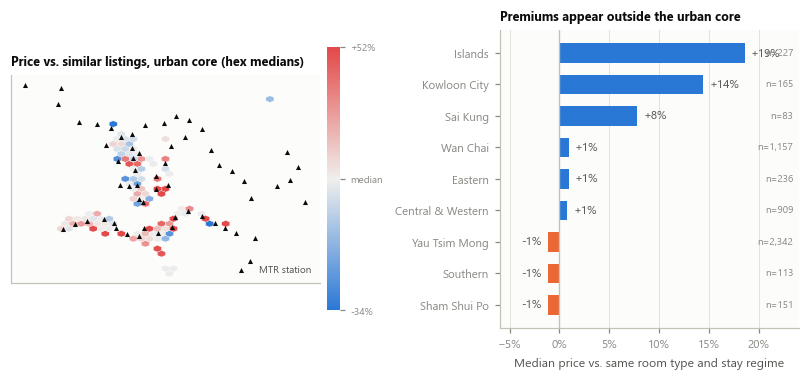

             rel     n
mtr_band              
< 250 m    0.990  2217
250-500 m  1.011  2252
0.5-1 km   1.017   547
1-2 km     1.056   138
2+ km      0.988   401
Median distance to nearest MTR station: 290 m; 80% of listings are within 500 m


In [6]:
# Relative price: price divided by the median price of listings with the same room type AND stay regime. This removes the
# (huge) regime/room-type effect so that the map and distance chart show the *location* premium only.
df = df.join(GEO)
df["price_rel"] = df.price_hkd / df.groupby(["room_type", "regime"]).price_hkd.transform("median")

from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("bluered", [PAL["blue"], "#f0efec", PAL["red"]])

fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.5), gridspec_kw=dict(width_ratios=[1.1, 1]))
a = ax[0]
core = df[(df.longitude.between(114.10, 114.27)) & (df.latitude.between(22.255, 22.36))]
hb = a.hexbin(core.longitude, core.latitude, C=np.log2(core.price_rel), reduce_C_function=np.median, gridsize=34, mincnt=6,
              cmap=div, vmin=-0.6, vmax=0.6, linewidths=0.2, edgecolors="white")
m_core = MTR[(MTR.lon.between(114.10, 114.27)) & (MTR.lat.between(22.255, 22.36))]
a.scatter(m_core.lon, m_core.lat, marker="^", s=11, color=PAL["ink"], label="MTR station", linewidths=0, zorder=3)
a.set_aspect(1 / np.cos(np.radians(22.3))); a.grid(False); a.set_xticks([]); a.set_yticks([])
a.set_title("Price vs. similar listings, urban core (hex medians)", fontsize=8.2)
cb = fig.colorbar(hb, ax=a, fraction=0.04, pad=0.02, ticks=[-0.6, 0, 0.6])
cb.ax.set_yticklabels(["-34%", "median", "+52%"], fontsize=6.5); cb.outline.set_visible(False)
a.legend(loc="lower right", fontsize=6.5)

b = ax[1]
dist_tbl = (df.groupby("neighbourhood_cleansed").agg(n=("price_rel", "size"), rel=("price_rel", "median"))
              .query("n >= 80").sort_values("rel"))
cols_b = [PAL["blue"] if v >= 1.0 else PAL["orange"] for v in dist_tbl.rel]
b.barh(dist_tbl.index, dist_tbl.rel - 1, color=cols_b, height=0.62)
for i, (v, n) in enumerate(zip(dist_tbl.rel - 1, dist_tbl.n)):
    b.text(v + (0.006 if v >= 0 else -0.006), i, f"{v*100:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=7.5)
    b.text(0.235, i, f"n={n:,}", va="center", ha="right", fontsize=6.5, color=PAL["muted"])
b.axvline(0, color=PAL["axis"], lw=0.9); b.set_xlim(-0.06, 0.24)
b.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); b.grid(axis="y", visible=False)
b.set_xlabel("Median price vs. same room type and stay regime")
b.set_title("Premiums appear outside the urban core", fontsize=8.2)
fig.tight_layout(w_pad=1.0)
savefig("fig2_geography", fig)

edges = [0, 0.25, 0.5, 1.0, 2.0, 50]
df["mtr_band"] = pd.cut(df.dist_mtr_km, edges, labels=["< 250 m", "250-500 m", "0.5-1 km", "1-2 km", "2+ km"])
bb = df.groupby("mtr_band").agg(rel=("price_rel", "median"), n=("price_rel", "size"))
RESULTS["geo"] = dict(n_stations=int(len(MTR)), median_dist_mtr_m=float(df.dist_mtr_km.median() * 1000),
                      share_within_500m=float((df.dist_mtr_km <= 0.5).mean()),
                      band_rel_price={str(k): float(v) for k, v in bb.rel.items()}, band_n={str(k): int(v) for k, v in bb.n.items()},
                      district_rel_price={k: float(v) for k, v in dist_tbl.rel.items()})
print(bb.round(3))
print(f"Median distance to nearest MTR station: {df.dist_mtr_km.median()*1000:.0f} m; {pct((df.dist_mtr_km<=0.5).mean())} of listings are within 500 m")

**Business reading (an honest, partly negative finding).** Raw medians show **no simple "closer to the MTR = more
expensive" gradient**: 40% of listings are within 250 m of a station and half within 300 m, because supply itself is
located where the transit is. Price premiums *relative to similar listings* appear mostly **outside the urban core**
(Islands, Kowloon City, Sai Kung), where listings are scarcer and more often whole homes for holidays. This is a first warning
that location effects are entangled with *what kind of property* is offered, which is exactly why a multivariate model –
and not a chart of averages – is needed to separate them (sections 9 and 12).

## 6. Useful factors: what could explain a listing's price, and why?

We organise candidate factors into **families**, each tied to a business rationale. Grouping them matters: later we measure
how much each *family* adds (ablation) and how much accuracy is lost when it is scrambled (permutation importance), which is
a far more useful business statement than "feature 37 has importance 0.02".

| Family | Factors | Business rationale (hedonic pricing: a listing is a bundle of attributes guests value) |
|---|---|---|
| **Property & capacity** | room type, property type, guests, bedrooms, beds, baths, shared bathroom | Space and privacy are what guests buy |
| **Stay policy & quote** | long-stay (≥ 28 nights), log minimum nights, nights in the quoted stay, weekend check-in | Determines the customer segment (tourists vs. monthly renters). The scraped price is a *quote for a specific stay*, and Fri/Sat check-ins and longer stays are priced differently; the quote variables are **measurement controls**, set to a standard stay when benchmarking |
| **Location** | district, region, latitude/longitude | Neighbourhood prestige and demand |
| **Transit & centrality** | distance to nearest MTR, MTR stations within 1 km, distance to Central / TST / nearest of 4 hubs | Hong Kong is a transit city |
| **Local competition** | listings within 500 m and 1 km | Dense areas = more substitutes = price pressure (or a proven tourist area) |
| **Amenities** | 30 most common amenity flags + total count | Convenience features guests trade money for |
| **Host profile** | professional host (5+ listings), host lives in Hong Kong | Professional operators price differently from occasional hosts. *Decision:* we first built six host variables (portfolio size, tenure, verification, profile text…) but kept only these two flags: in host-grouped cross-validation the richer set did **not** improve accuracy (typical error 22.8% vs 22.2% without), because continuous host-history variables let a tree recognise individual professional hosts, which does not generalise to hosts it has never seen |
| **Listing text** | keyword flags in title/description, description length | How the listing is *marketed* (luxury, view, MTR…) |

*Deliberately excluded:* the quote's **lead time** (days until the quoted check-in) – the next free date is partly an *outcome* of demand (busy listings are booked up), so using it would leak demand into price.

Two further families exist only **after** a listing has guests – `Reviews & ratings` and `Guest voice` (what guests write).
A new host does not have them, so they are **excluded from the main "new-listing benchmark"** and used only for a second
model for *existing* listings (section 14). This separation is deliberate: it keeps the benchmark honest for its main user.

In [7]:
# --- grouping decisions (made on the modelling sample only, using counts - never the price) ---
ptype_counts = df.property_type.value_counts()
TOP_PTYPES = ptype_counts[ptype_counts >= 50].index.tolist()
dist_counts = df.neighbourhood_cleansed.value_counts()
KEEP_DISTRICTS = dist_counts[dist_counts >= 60].index.tolist()
REGION = {**{d: "Hong Kong Island" for d in ["Central & Western", "Wan Chai", "Eastern", "Southern"]},
          **{d: "Kowloon" for d in ["Yau Tsim Mong", "Sham Shui Po", "Kowloon City", "Wong Tai Sin", "Kwun Tong"]}}
print(f"{len(TOP_PTYPES)} property types kept ({pct(df.property_type.isin(TOP_PTYPES).mean())} of listings), rest -> 'Other'")
print(f"{len(KEEP_DISTRICTS)} districts kept ({pct(df.neighbourhood_cleansed.isin(KEEP_DISTRICTS).mean())} of listings), rest -> 'Other districts'")

# --- amenities: parse the JSON list and flag the most common ones ---
def parse_list(s):
    try: return json.loads(s)
    except Exception: return []

amen_lists = L.amenities.apply(parse_list)
amen_prev = pd.Series([a for l in amen_lists.loc[df.index] for a in l]).value_counts() / len(df)
AMEN = amen_prev[(amen_prev >= 0.05) & (amen_prev <= 0.97)].head(30).index.tolist()
slug = lambda s: "am_" + re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")
AMEN_COLS = {a: slug(a) for a in AMEN}
print(f"{len(amen_prev)} distinct amenities; {len(AMEN)} flagged (prevalence 5-97%): {AMEN[:8]} ...")

TEXT_FLAGS = {  # marketing keywords in title + description
    "tx_transit": r"\bmtr\b|\bstation\b|\bsubway\b|\bmetro\b",
    "tx_luxury": r"luxur|premium|high-end|deluxe|boutique",
    "tx_view": r"\bview|harbou?r|\bsea\b|skyline|rooftop",
    "tx_studio": r"\bstudio\b",
    "tx_renovated": r"brand new|newly|renovat|modern",
    "tx_family": r"\bfamily|\bkids\b|\bchildren\b",
    "tx_monthly": r"monthly|long[- ]?term|per month|\bmonth\b",
    "tx_hostel": r"hostel|dorm|bunk|capsule",
    "tx_tiny": r"\btiny\b|\bcompact\b|\bcozy\b|\bcosy\b|\bsmall\b",
}

def engineer(Lsrc):
    """Builds the factor table for any subset of listings (index preserved)."""
    X = pd.DataFrame(index=Lsrc.index)
    # property & capacity
    X["room_type"] = Lsrc.room_type
    X["property_type_grp"] = Lsrc.property_type.where(Lsrc.property_type.isin(TOP_PTYPES), "Other")
    X["accommodates"] = Lsrc.accommodates
    X["bedrooms"] = Lsrc.bedrooms
    X["studio"] = (Lsrc.bedrooms == 0).astype(int)
    X["beds"] = Lsrc.beds
    txt = Lsrc.bathrooms_text.fillna("").str.lower()
    X["baths"] = txt.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
    X.loc[txt.str.contains("half") & X["baths"].isna(), "baths"] = 0.5
    X["bath_shared"] = txt.str.contains("shared").astype(int)
    # stay policy
    X["long_stay"] = (Lsrc.minimum_nights >= 28).astype(int)
    X["log_min_nights"] = np.log(Lsrc.minimum_nights.clip(lower=1))
    # quote context (properties of the scraped price quote, not of the listing)
    q_in, q_out = pd.to_datetime(Lsrc.price_quote_checkin_date), pd.to_datetime(Lsrc.price_quote_checkout_date)
    q_nights = (q_out - q_in).dt.days
    X["q_log_nights"] = np.log(q_nights.where(q_nights >= 1, Lsrc.minimum_nights).clip(lower=1))
    X["q_weekend"] = q_in.dt.dayofweek.isin([4, 5]).astype(int)       # Friday / Saturday check-in
    # location
    X["district_grp"] = Lsrc.neighbourhood_cleansed.where(Lsrc.neighbourhood_cleansed.isin(KEEP_DISTRICTS), "Other districts")
    X["region"] = Lsrc.neighbourhood_cleansed.map(REGION).fillna("New Territories & Islands")
    X["lat"], X["lon"] = Lsrc.latitude, Lsrc.longitude
    # transit & centrality / competition (computed on the full file in section 5)
    for c in ["dist_mtr_km", "n_mtr_1km", "dist_central_km", "dist_tst_km", "dist_hub_min_km", "listings_500m", "listings_1km"]:
        X[c] = GEO.loc[Lsrc.index, c]
    # amenities
    al = amen_lists.loc[Lsrc.index]
    for a, c in AMEN_COLS.items():
        X[c] = al.apply(lambda l, a=a: int(a in l))
    X["n_amenities"] = al.apply(len)
    # host profile
    X["pro_host"] = (Lsrc.calculated_host_listings_count >= 5).astype(int)
    X["host_local"] = Lsrc.host_location.fillna("").str.contains("Hong Kong").astype(int)
    # listing text
    blob = (Lsrc.name.fillna("") + " " + Lsrc.description.fillna("")).str.lower()
    for c, rx in TEXT_FLAGS.items():
        X[c] = blob.str.contains(rx, regex=True).astype(int)
    X["desc_words_log"] = np.log1p(Lsrc.description.fillna("").str.split().str.len())
    return X

X_all = engineer(df)

CAT_COLS = ["room_type", "property_type_grp", "district_grp", "region"]
FAMILIES = {
    "Property & capacity": ["room_type", "property_type_grp", "accommodates", "bedrooms", "studio", "beds", "baths", "bath_shared"],
    "Stay policy & quote": ["long_stay", "log_min_nights", "q_log_nights", "q_weekend"],
    "Location": ["district_grp", "region", "lat", "lon"],
    "Transit & centrality": ["dist_mtr_km", "n_mtr_1km", "dist_central_km", "dist_tst_km", "dist_hub_min_km"],
    "Local competition": ["listings_500m", "listings_1km"],
    "Amenities": list(AMEN_COLS.values()) + ["n_amenities"],
    "Host profile": ["pro_host", "host_local"],
    "Listing text": list(TEXT_FLAGS) + ["desc_words_log"],
}
NEW_COLS = [c for fam in FAMILIES.values() for c in fam]
assert set(NEW_COLS) == set(X_all.columns), set(X_all.columns) ^ set(NEW_COLS)
print({k: len(v) for k, v in FAMILIES.items()}, "-> total", len(NEW_COLS), "launch-time factors")
RESULTS["features"] = dict(families={k: len(v) for k, v in FAMILIES.items()}, n_total=len(NEW_COLS), amenities_flagged=AMEN,
                           top_property_types=TOP_PTYPES, kept_districts=KEEP_DISTRICTS)
display(X_all[["accommodates", "bedrooms", "baths", "bath_shared", "dist_mtr_km", "dist_central_km", "listings_500m", "n_amenities", "pro_host"]].describe().T[["mean", "50%", "min", "max"]].round(2))
print(f"Weekend check-in share of quotes: short stays {pct(X_all.loc[X_all.long_stay==0,'q_weekend'].mean())}, long stays {pct(X_all.loc[X_all.long_stay==1,'q_weekend'].mean())}")
print("Missing values in launch-time factors:", X_all[NEW_COLS].isna().sum()[lambda s: s > 0].to_dict(), "(imputed with the training median inside the pipeline)")

11 property types kept (94% of listings), rest -> 'Other'
9 districts kept (97% of listings), rest -> 'Other districts'
835 distinct amenities; 30 flagged (prevalence 5-97%): ['Wifi', 'Air conditioning', 'Kitchen', 'Hot water', 'Hangers', 'Hair dryer', 'TV', 'Washer'] ...


{'Property & capacity': 8, 'Stay policy & quote': 4, 'Location': 4, 'Transit & centrality': 5, 'Local competition': 2, 'Amenities': 31, 'Host profile': 2, 'Listing text': 10} -> total 66 launch-time factors


,mean,50%,min,max
accommodates,2.60,2.00,1.00,16.00
bedrooms,1.15,1.00,0.00,14.00
baths,1.11,1.00,0.00,10.00
bath_shared,0.26,0.00,0.00,1.00
dist_mtr_km,0.63,0.29,0.00,12.58
dist_central_km,4.04,2.88,0.17,31.30
listings_500m,421.51,488.00,0.00,949.00
n_amenities,17.54,14.00,0.00,76.00
pro_host,0.76,1.00,0.00,1.00


Weekend check-in share of quotes: short stays 46%, long stays 80%
Missing values in launch-time factors: {'bedrooms': 19, 'beds': 97, 'baths': 19} (imputed with the training median inside the pipeline)


## 7. Factors that only exist after the first guests: ratings and the "voice of the guest"

Reviews are a second, richer data source (122k comments). They cannot be inputs to the *new-listing* benchmark (a new host
has none) but they tell us (a) whether a listing priced above or below benchmark is **also perceived differently by
guests**, and (b) whether an *existing* listing's price can be explained better once reputation is known.

*Data-quality decisions for the text:*
* Reviews are multilingual. We keep **English-like comments** (≥ 97% ASCII characters, ≥ 20 characters) for lexicon-based
  analysis; the share we keep is reported, not hidden.
* Sentiment uses **VADER** (a lexicon-based scorer designed for short reviews) – transparent and requires no training data.
* Topic flags are regular expressions for what matters in Hong Kong's small-flat market: *location/transit, cleanliness,
  dirt/smell, noise, small size, value for money, "overpriced" complaints and host service.*
* A listing gets text features only if it has **≥ 3 English reviews** (otherwise the share would be noise).

In [8]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

TOPICS = {
    "gv_location": r"location|located|\bwalk|\bmtr\b|station|convenient|close to|\bnear\b",
    "gv_clean": r"\bclean|spotless|\btidy\b|well[- ]kept",
    "gv_dirty": r"\bdirty|smell|\bmold|\bmould|cockroach|\bbugs?\b|stain|filthy|\bdust",
    "gv_noise": r"\bnois|\bloud\b|thin wall",
    "gv_small": r"\bsmall\b|\btiny\b|cramped|narrow|\bcompact\b|little space|shoebox",
    "gv_value": r"great value|good value|worth|affordable|\bcheap\b|bargain|value for money",
    "gv_pricey": r"expensive|overpriced|pricey|not worth|rip[- ]?off|too much",
    "gv_host": r"helpful|responsive|friendly|attentive|great host|communicat",
}
cache_rev = OUT / "review_features.csv"
if cache_rev.exists():
    GV = pd.read_csv(cache_rev, index_col=0)
else:
    t0 = time.time()
    R2 = R.dropna(subset=["comments"]).copy()
    R2["txt"] = R2.comments.str.replace(r"<[^>]+>", " ", regex=True)
    ascii_share = R2.txt.apply(lambda s: sum(ord(ch) < 128 for ch in s) / max(len(s), 1))
    R2["english"] = (ascii_share >= 0.97) & (R2.txt.str.len() >= 20)
    E = R2[R2.english].copy()
    low = E.txt.str.lower()
    for c, rx in TOPICS.items():
        E[c] = low.str.contains(rx, regex=True).astype(int)
    sia = SentimentIntensityAnalyzer()
    E["gv_sentiment"] = E.txt.apply(lambda s: sia.polarity_scores(s)["compound"])
    agg = E.groupby("listing_id").agg(n_en=("txt", "size"), gv_sentiment=("gv_sentiment", "mean"), **{c: (c, "mean") for c in TOPICS})
    agg = agg[agg.n_en >= 3]
    GV = agg
    GV.to_csv(cache_rev)
    print(f"processed {len(R2):,} reviews in {time.time()-t0:.0f}s")
GV_COLS = ["gv_sentiment"] + list(TOPICS)
R_en_share = float((R.comments.fillna("").apply(lambda s: sum(ord(ch) < 128 for ch in s) / max(len(s), 1)) >= 0.97).mean())
print(f"English-like share of review comments: {pct(R_en_share)}; listings with >=3 English reviews: {len(GV):,}")

def experience(Lsrc):
    """'Existing listing' factors: ratings, review activity and guest-voice text features."""
    E_ = pd.DataFrame(index=Lsrc.index)
    for c in ["accuracy", "cleanliness", "checkin", "communication", "location", "value", "rating"]:
        E_[f"rs_{c}"] = Lsrc[f"review_scores_{c}"]
    E_["log_n_reviews"] = np.log1p(Lsrc.number_of_reviews)
    E_["reviews_ltm"] = Lsrc.number_of_reviews_ltm
    E_["reviews_per_month"] = Lsrc.reviews_per_month
    E_["days_since_last_review"] = (SCRAPE_DATE - Lsrc.last_review).dt.days
    E_["superhost"] = (Lsrc.host_is_superhost == "t").astype(int)
    E_["has_reviews"] = (Lsrc.number_of_reviews > 0).astype(int)
    gv = GV.reindex(Lsrc.id.values)
    gv.index = Lsrc.index
    for c in GV_COLS:
        E_[c] = gv[c]
    return E_

EXP_FAMILIES = {
    "Reviews & ratings": [f"rs_{c}" for c in ["accuracy", "cleanliness", "checkin", "communication", "location", "value", "rating"]]
                         + ["log_n_reviews", "reviews_ltm", "reviews_per_month", "days_since_last_review", "superhost", "has_reviews"],
    "Guest voice (review text)": GV_COLS,
}
EXP_ALL = experience(df)
EXP_COLS = [c for v in EXP_FAMILIES.values() for c in v]
print(f"Listings with rating data: {pct(EXP_ALL.rs_rating.notna().mean())};  with guest-voice text features: {pct(EXP_ALL.gv_sentiment.notna().mean())}")
RESULTS["reviews"] = dict(share_english=R_en_share, n_listings_gv=int(len(GV)), share_with_rating=float(EXP_ALL.rs_rating.notna().mean()),
                          share_with_gv=float(EXP_ALL.gv_sentiment.notna().mean()), n_reviews=int(len(R)))

English-like share of review comments: 61%; listings with >=3 English reviews: 2,372
Listings with rating data: 55%;  with guest-voice text features: 36%


## 8. Market segments – unsupervised learning (KMeans + PCA, Week 6)

*Business question:* "Which kinds of listings really exist in this market, and do they behave differently on price?"
If the market is made of a few distinct *segments*, a host should benchmark against their own segment, and an investor
should choose a segment before choosing a district.

*Design decisions.*
* **Price is deliberately NOT an input.** Clustering on the characteristics of the offer (size, room type, stay policy,
  centrality, operator type, amenities, local density) means that price differences between segments are a *finding*,
  not something we put in.
* Inputs are standardised (KMeans is distance-based) and skewed distances are log-transformed.
* We choose the number of clusters *k* with the silhouette score, but only among **k = 4…7** and only if **every segment holds at
  least 3% of listings**: the business needs enough segments to be actionable, but a segment of 28 listings is not a market.
* PCA is used only to *draw* the clusters in two dimensions.

  File "C:\Users\Elias\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

silhouette by k: {3: 0.217, 4: 0.224, 5: 0.231, 6: 0.231, 7: 0.237, 8: 0.248}
smallest segment share by k: {3: 0.098, 4: 0.083, 5: 0.075, 6: 0.072, 7: 0.005, 8: 0.005} -> eligible [4, 5, 6] -> chosen k = 5


,n,median_price,entire,long_stay,guests,bedrooms,dist_central,shared_bath,pro_host,amenities,label
seg_id,,,,,,,,,,,
1,1752,174.42,0.01,0.97,1.0,1.0,3.03,0.50,0.98,6.0,"Private rooms, monthly"
0,1645,500.00,0.00,0.04,2.0,1.0,2.73,0.27,0.83,16.0,"Private rooms, short-stay"
4,1178,739.50,1.00,0.37,2.0,1.0,2.60,0.00,0.61,22.0,"Whole units, mixed stay"
2,414,786.52,0.53,0.16,2.0,1.0,15.63,0.24,0.25,19.0,"Mixed units, short-stay, outer areas"
3,566,1469.80,0.93,0.16,7.0,2.0,2.93,0.02,0.55,29.0,"Whole units, short-stay, groups"


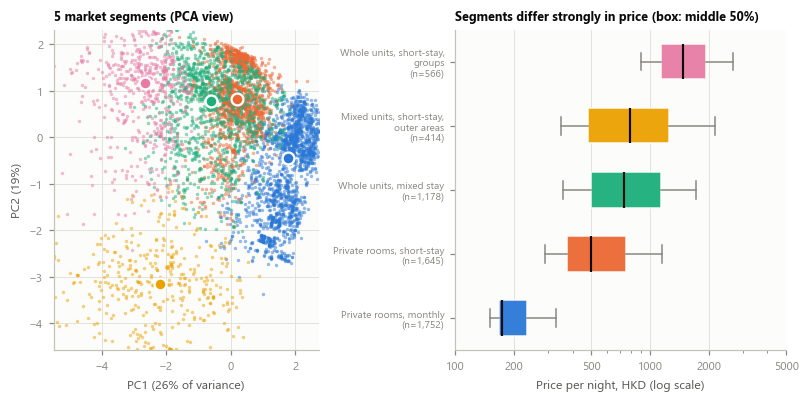

In [9]:
seg_in = pd.DataFrame({
    "accommodates": X_all.accommodates, "bedrooms": X_all.bedrooms.fillna(1), "baths": X_all.baths.fillna(1), "bath_shared": X_all.bath_shared,
    "is_entire": (X_all.room_type == "Entire home/apt").astype(int), "log_min_nights": X_all.log_min_nights,
    "log_dist_central": np.log1p(X_all.dist_central_km), "log_dist_mtr": np.log1p(X_all.dist_mtr_km),
    "host_listings": np.log1p(df.calculated_host_listings_count), "n_amenities": X_all.n_amenities, "listings_500m": X_all.listings_500m,
})
Z = StandardScaler().fit_transform(seg_in)
sil, min_share = {}, {}
for k in range(3, 9):
    km_ = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    sil[k] = silhouette_score(Z, km_.labels_, sample_size=3000, random_state=RANDOM_STATE)
    min_share[k] = np.bincount(km_.labels_).min() / len(Z)
# business constraint: every segment must be big enough to matter (>= 3% of listings)
eligible = [k for k in range(4, 8) if min_share[k] >= 0.03]
K_SEG = max(eligible, key=lambda k: sil[k])
print("silhouette by k:", {k: round(v, 3) for k, v in sil.items()})
print("smallest segment share by k:", {k: round(v, 3) for k, v in min_share.items()}, "-> eligible", eligible, "-> chosen k =", K_SEG)
km = KMeans(n_clusters=K_SEG, n_init=20, random_state=RANDOM_STATE).fit(Z)
df["seg_id"] = km.labels_

prof = df.assign(entire=X_all.room_type.eq("Entire home/apt"), long=X_all.long_stay, acc=X_all.accommodates, bed=X_all.bedrooms,
                 dc=X_all.dist_central_km, shared=X_all.bath_shared, pro=X_all.pro_host, amen=X_all.n_amenities).groupby("seg_id").agg(
    n=("price_hkd", "size"), median_price=("price_hkd", "median"), entire=("entire", "mean"), long_stay=("long", "mean"),
    guests=("acc", "median"), bedrooms=("bed", "median"), dist_central=("dc", "median"), shared_bath=("shared", "mean"),
    pro_host=("pro", "mean"), amenities=("amen", "median"))

def label_segment(r):
    room = "Whole units" if r.entire > 0.6 else ("Private rooms" if r.entire < 0.25 else "Mixed units")
    stay = "monthly" if r.long_stay > 0.65 else ("short-stay" if r.long_stay < 0.35 else "mixed stay")
    mod = ""
    if r.guests >= 4: mod = ", groups"
    elif r.dist_central > 7: mod = ", outer areas"
    elif r.shared_bath > 0.5 and r.entire < 0.25: mod = ", shared bath"
    return f"{room}, {stay}{mod}"

prof["label"] = prof.apply(label_segment, axis=1)
dup = prof.label.duplicated(keep=False)
prof.loc[dup, "label"] = prof.loc[dup].apply(lambda r: r.label + f" (median {r.median_price:,.0f} HKD)", axis=1)
prof = prof.sort_values("median_price")
df["segment"] = df.seg_id.map(prof.label)
display(prof.round(2))

# --- figure 3: PCA map of segments + price distribution per segment ---
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z)
P = pca.transform(Z)
order = list(prof.index)
colors = {sid: CAT[i % len(CAT)] for i, sid in enumerate(order)}
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.7), gridspec_kw=dict(width_ratios=[1, 1.25]))
a = ax[0]
for sid in order:
    m = df.seg_id.values == sid
    a.scatter(P[m, 0], P[m, 1], s=5, alpha=0.5, color=colors[sid], linewidths=0)
for sid in order:
    m = df.seg_id.values == sid
    a.scatter(*np.median(P[m], axis=0), s=60, color=colors[sid], edgecolor="white", linewidth=1.5, zorder=3)
a.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% of variance)"); a.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}%)")
a.set_xlim(np.percentile(P[:, 0], [0.5, 99.5])); a.set_ylim(np.percentile(P[:, 1], [0.5, 99.5]))
a.set_title(f"{K_SEG} market segments (PCA view)", fontsize=8.2)
b = ax[1]
data = [df.loc[df.seg_id == sid, "price_hkd"].values for sid in order]
bp = b.boxplot(data, vert=False, patch_artist=True, widths=0.55, showfliers=False, whis=(10, 90),
               medianprops=dict(color=PAL["ink"], lw=1.4), whiskerprops=dict(color=PAL["muted"]), capprops=dict(color=PAL["muted"]))
for patch, sid in zip(bp["boxes"], order):
    patch.set_facecolor(colors[sid]); patch.set_edgecolor(PAL["surface"]); patch.set_alpha(0.95)
b.set_xscale("log"); b.set_xticks([100, 200, 500, 1000, 2000, 5000]); b.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
short = {sid: textwrap.fill(prof.loc[sid, "label"], 26) for sid in order}
b.set_yticklabels([short[s] + f"\n(n={int(prof.loc[s,'n']):,})" for s in order], fontsize=6.6)
b.set_xlabel("Price per night, HKD (log scale)"); b.grid(axis="y", visible=False)
b.set_title("Segments differ strongly in price (box: middle 50%)", fontsize=8.2)
fig.tight_layout(w_pad=1.2)
savefig("fig3_segments", fig)

RESULTS["segments"] = dict(k=K_SEG, silhouette={int(k): float(v) for k, v in sil.items()},
                           profile=[dict(label=r.label, n=int(r.n), share=float(r.n / len(df)), median_price=float(r.median_price), entire=float(r.entire),
                                         long_stay=float(r.long_stay), guests=float(r.guests), bedrooms=float(r.bedrooms),
                                         dist_central=float(r.dist_central), pro_host=float(r.pro_host)) for _, r in prof.iterrows()],
                           pca_var=[float(v) for v in pca.explained_variance_ratio_])

## 9. Supervised learning: designing a benchmark that is *honest* for a real user

**Target.** `log(price per night)`. Errors then read as percentages, which is how hosts think ("20% above market"), and
the skewed HKD distribution stops a few expensive listings from dominating the fit. All results are reported back in HKD.

**Evaluation design – the three decisions that protect the credibility of the result**
1. **Split by host, not by listing.** A professional host with 40 near-identical listings would otherwise appear in both
   train and test and the model would be rewarded for memorising a host. All listings of a host go to the *same* side
   (`GroupShuffleSplit`, 80/20) and cross-validation also respects hosts (`GroupKFold`). The test set is touched **once**.
2. **All preprocessing lives inside a `Pipeline`.** Imputation values, scaling and one-hot categories are learned on the training
   folds only, so no information leaks from validation/test data.
3. **Model selection uses cross-validation on the training data only**; the test set is used only to report final performance.

**Models (and why).**
| Model | Why it is in the comparison |
|---|---|
| *Comparable-listings baseline* | What hosts do today: the median price of listings in the same district, room type and stay regime. Any ML model must beat this to be worth building |
| **Ridge regression** (regularised linear) | Transparent, stable with many correlated dummies (amenities); shows how far a purely linear logic gets |
| **Random forest** | Captures non-linear effects and interactions (e.g. a bedroom is worth more on HK Island) without hand-made terms |
| **Gradient boosting** (`HistGradientBoostingRegressor`) | Usually the strongest model on tabular data; sequentially corrects residuals |
| **Blend (RF + GB)** | Averages two different error profiles |

**Metrics (business first).** *MAE* in HKD (typical size of the error), *median absolute % error* (typical relative miss),
*share of listings predicted within ±20%* (a host's practical "is this price about right?"), plus RMSE and R² for completeness.

In [10]:
y = np.log(df.price_hkd.values)
groups = df.host_id.values
# A single random split by host can be badly unbalanced because a few hosts own hundreds of listings (one host: 344). We therefore
# draw 300 candidate host-level splits and keep the one whose test set best mirrors the full sample in stay regime, room type and
# price level. This uses only the *composition* of the data, never any model result.
def split_imbalance(te_i):
    t = np.zeros(len(y), bool); t[te_i] = True
    return (abs(X_all.long_stay[t].mean() - X_all.long_stay.mean()) / 0.04
            + abs((X_all.room_type[t] == "Entire home/apt").mean() - (X_all.room_type == "Entire home/apt").mean()) / 0.04
            + abs(np.median(y[t]) - np.median(y)) / 0.08 + abs(t.mean() - 0.2) / 0.02)
cands = {}
for seed in range(300):
    tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(X_all, y, groups=groups))
    cands[seed] = (split_imbalance(te_i), tr_i, te_i)
SPLIT_SEED = min(cands, key=lambda k: cands[k][0])
_, tr, te = cands[SPLIT_SEED]
print(f"chosen split seed {SPLIT_SEED} (imbalance score {cands[SPLIT_SEED][0]:.2f}; median over 300 candidates {np.median([v[0] for v in cands.values()]):.2f})")
assert not set(groups[tr]) & set(groups[te]), "host leakage between train and test!"
Xtr, Xte, ytr, yte, gtr = X_all.iloc[tr], X_all.iloc[te], y[tr], y[te], groups[tr]
ptr, pte = np.exp(ytr), np.exp(yte)
print(f"train {len(tr):,} listings / {len(set(gtr)):,} hosts | test {len(te):,} listings / {len(set(groups[te])):,} hosts | hosts shared: 0")
print("median price train vs test:", round(np.median(ptr)), "vs", round(np.median(pte)),
      "| long-stay share:", pct(Xtr.long_stay.mean()), "vs", pct(Xte.long_stay.mean()))
RESULTS["split"] = dict(seed=int(SPLIT_SEED), n_train=len(tr), n_test=len(te), hosts_train=len(set(gtr)), hosts_test=len(set(groups[te])),
                        test_size=0.2, cv_folds=5)

def make_pre(cols, scale=False):
    cat = [c for c in cols if c in CAT_COLS]
    num = [c for c in cols if c not in CAT_COLS]
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                         ("sc", StandardScaler() if scale else "passthrough")])
    return ColumnTransformer([("num", num_pipe, num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False), cat)])

def make_pipe(cols, model, scale=False):
    return Pipeline([("pre", make_pre(cols, scale)), ("model", model)])

def metrics(p_true, p_pred):
    e = p_pred - p_true
    ape = np.abs(e) / p_true
    lt, lp = np.log(p_true), np.log(p_pred)
    return dict(MAE=float(np.mean(np.abs(e))), RMSE=float(np.sqrt(np.mean(e ** 2))),
                R2=float(1 - np.sum(e ** 2) / np.sum((p_true - p_true.mean()) ** 2)),
                R2_log=float(1 - np.sum((lt - lp) ** 2) / np.sum((lt - lt.mean()) ** 2)),
                MedAPE=float(np.median(ape)), Within20=float(np.mean(ape <= 0.20)), Within30=float(np.mean(ape <= 0.30)))

class CompsBaseline:
    """What a host does by hand: median price of 'comparable' listings; falls back to coarser groups when a cell is thin."""
    LEVELS = [["district_grp", "room_type", "long_stay"], ["room_type", "long_stay"], ["long_stay"]]
    def __init__(self, levels=None, min_n=5): self.levels, self.min_n = levels or self.LEVELS, min_n
    def fit(self, X, price):
        d = X.assign(_p=np.asarray(price)); self.tables_ = []
        for lv in self.levels:
            t = d.groupby(lv)._p.agg(["median", "size"]); self.tables_.append((lv, t[t["size"] >= self.min_n]["median"]))
        self.global_ = float(np.median(price)); return self
    def predict(self, X):
        out = pd.Series(np.nan, index=X.index)
        for lv, t in self.tables_:
            key = pd.MultiIndex.from_frame(X[lv]) if len(lv) > 1 else X[lv[0]]
            vals = pd.Series(t.reindex(key).values, index=X.index)
            out = out.fillna(vals)
        return out.fillna(self.global_).values

chosen split seed 197 (imbalance score 1.15; median over 300 candidates 9.36)
train 4,386 listings / 940 hosts | test 1,169 listings / 235 hosts | hosts shared: 0
median price train vs test: 462 vs 491 | long-stay share: 43% vs 43%


In [11]:
cv = GroupKFold(n_splits=5)
t0 = time.time()
SEARCH = {
    "Ridge": (make_pipe(NEW_COLS, Ridge(random_state=RANDOM_STATE), scale=True),
              {"model__alpha": np.logspace(-1, 2.5, 25)}, 15),
    "Random forest": (make_pipe(NEW_COLS, RandomForestRegressor(n_estimators=250, random_state=RANDOM_STATE, n_jobs=1)),
                      {"model__min_samples_leaf": [1, 2, 3, 5, 8], "model__max_features": [0.2, 0.35, 0.5, 0.7, 1.0],
                       "model__max_depth": [None, 12, 20]}, 10),
    "Gradient boosting": (make_pipe(NEW_COLS, HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
                          {"model__learning_rate": [0.03, 0.05, 0.08, 0.12], "model__max_iter": [200, 350, 500],
                           "model__max_leaf_nodes": [8, 15, 31], "model__min_samples_leaf": [10, 20, 40],
                           "model__l2_regularization": [0, 0.1, 1, 5], "model__max_depth": [None, 6, 10]}, 20),
}
import os, joblib
tuned, cv_scores, best_params = {}, {}, {}
CACHE_TUNED = OUT / "_tuned_cache.joblib"          # development shortcut only (set IS3240_CACHE=1); a normal run always re-tunes
if os.environ.get("IS3240_CACHE") == "1" and CACHE_TUNED.exists():
    tuned, cv_scores, best_params = joblib.load(CACHE_TUNED)
else:
    for name, (pipe, space, n_iter) in SEARCH.items():
        rs = RandomizedSearchCV(pipe, space, n_iter=n_iter, cv=cv, scoring="neg_mean_absolute_error",
                                random_state=RANDOM_STATE, n_jobs=-1, refit=True)
        rs.fit(Xtr, ytr, groups=gtr)
        tuned[name], cv_scores[name], best_params[name] = rs.best_estimator_, -rs.best_score_, rs.best_params_
    if os.environ.get("IS3240_CACHE") == "1":
        joblib.dump((tuned, cv_scores, best_params), CACHE_TUNED)
for name in SEARCH:
    print(f"{name:18s} CV MAE (log-price) = {cv_scores[name]:.3f}   best: { {k.split('__')[1]: v for k, v in best_params[name].items()} }")
print(f"tuning took {time.time()-t0:.0f}s")

Ridge              CV MAE (log-price) = 0.363   best: {'alpha': 161.55980984398747}
Random forest      CV MAE (log-price) = 0.308   best: {'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 20}
Gradient boosting  CV MAE (log-price) = 0.309   best: {'min_samples_leaf': 40, 'max_leaf_nodes': 31, 'max_iter': 350, 'max_depth': 6, 'learning_rate': 0.03, 'l2_regularization': 0}
tuning took 119s


In [12]:
# ---- final test-set evaluation (touched once) ----
preds = {}
preds["Global median"] = np.full(len(te), np.median(ptr))
comps = CompsBaseline().fit(Xtr, ptr)
preds["Comparable-listings baseline"] = comps.predict(Xte)
for name, est in tuned.items():
    preds[name] = np.exp(est.predict(Xte))
preds["Blend (RF + GB)"] = np.exp((np.log(preds["Random forest"]) + np.log(preds["Gradient boosting"])) / 2)

res = pd.DataFrame({k: metrics(pte, v) for k, v in preds.items()}).T
res["CV MAE (log)"] = pd.Series({**cv_scores})
display(res.round(3))
ML_NAMES = ["Ridge", "Random forest", "Gradient boosting"]
BEST = min(ML_NAMES, key=lambda n: cv_scores[n])        # selection by training-set CV, never by test score
print("Model selected by cross-validation:", BEST)
base_mae, best_mae = res.loc["Comparable-listings baseline", "MAE"], res.loc[BEST, "MAE"]
print(f"MAE: baseline {base_mae:.0f} HKD -> {BEST} {best_mae:.0f} HKD  ({pct(1-best_mae/base_mae)} lower)")
print(f"Median % error: baseline {pct(res.loc['Comparable-listings baseline','MedAPE'],1)} -> {pct(res.loc[BEST,'MedAPE'],1)};  within +-20%: {pct(res.loc['Comparable-listings baseline','Within20'])} -> {pct(res.loc[BEST,'Within20'])}")

# host-clustered bootstrap CI of the MAE reduction vs. the baseline (hosts are resampled, not listings)
rng = np.random.default_rng(RANDOM_STATE)
hid = pd.factorize(groups[te])[0]; nh = hid.max() + 1
ab_base, ab_best = np.abs(preds["Comparable-listings baseline"] - pte), np.abs(preds[BEST] - pte)
boot = []
for _ in range(2000):
    w = rng.multinomial(nh, np.ones(nh) / nh)[hid]
    boot.append(1 - (w * ab_best).sum() / (w * ab_base).sum())
ci = np.percentile(boot, [2.5, 97.5])
print(f"MAE reduction vs. baseline: {pct(1-best_mae/base_mae,1)}  (95% host-bootstrap CI {pct(ci[0],1)} to {pct(ci[1],1)})")

RESULTS["models"] = dict(table={k: {m: float(v) for m, v in r.items() if pd.notna(v)} for k, r in res.iterrows()},
                         best=BEST, best_params={k: {a.split('__')[1]: (float(b) if isinstance(b, (float, np.floating)) else b) for a, b in v.items()} for k, v in best_params.items()},
                         mae_reduction=float(1 - best_mae / base_mae), mae_reduction_ci=[float(ci[0]), float(ci[1])],
                         cv_mae_log={k: float(v) for k, v in cv_scores.items()})

,MAE,RMSE,R2,R2_log,MedAPE,Within20,Within30,CV MAE (log)
Global median,479.952,869.595,-0.148,-0.035,0.514,0.186,0.276,NaN
Comparable-listings baseline,353.545,713.680,0.227,0.511,0.326,0.332,0.457,NaN
Ridge,299.861,626.479,0.404,0.682,0.260,0.401,0.576,0.363
Random forest,280.032,590.136,0.471,0.716,0.247,0.433,0.581,0.308
Gradient boosting,269.814,557.638,0.528,0.732,0.228,0.441,0.609,0.309
Blend (RF + GB),271.637,570.824,0.505,0.730,0.233,0.435,0.598,NaN


Model selected by cross-validation: Random forest
MAE: baseline 354 HKD -> Random forest 280 HKD  (21% lower)
Median % error: baseline 32.6% -> 24.7%;  within +-20%: 33% -> 43%
MAE reduction vs. baseline: 20.8%  (95% host-bootstrap CI 15.6% to 26.7%)


In [13]:
# ---- performance by segment (test set) ----
def seg_table(by):
    d = pd.DataFrame({"g": by, "p": pte, "f": preds[BEST]})
    rows = []
    for k, s in d.groupby("g"):
        m = metrics(s.p.values, s.f.values)
        rows.append(dict(group=k, n=len(s), median_price=s.p.median(), MAE=m["MAE"], MedAPE=m["MedAPE"], Within20=m["Within20"]))
    return pd.DataFrame(rows).set_index("group")

reg_room = (X_all.iloc[te].room_type.where(X_all.iloc[te].room_type.isin(["Private room", "Entire home/apt"]), "Other") + " | " +
            np.where(Xte.long_stay == 1, "long stay", "short stay"))
seg_perf = seg_table(reg_room.values)
dist_perf = seg_table(Xte.district_grp.values).sort_values("n", ascending=False)
cluster_perf = seg_table(df.segment.iloc[te].values).sort_values("median_price")
display(seg_perf.round(3)); display(dist_perf.round(3)); display(cluster_perf.round(3))
RESULTS["models"]["by_regime_room"] = {k: {c: float(v) for c, v in r.items()} for k, r in seg_perf.iterrows()}
RESULTS["models"]["by_district"] = {k: {c: float(v) for c, v in r.items()} for k, r in dist_perf.iterrows()}
RESULTS["models"]["by_segment"] = {k: {c: float(v) for c, v in r.items()} for k, r in cluster_perf.iterrows()}

,n,median_price,MAE,MedAPE,Within20
group,,,,,
Entire home/apt | long stay,177,675.720,312.080,0.283,0.373
Entire home/apt | short stay,227,1288.400,494.302,0.247,0.419
Other | long stay,2,200.165,285.396,1.529,0.500
Other | short stay,21,410.000,179.507,0.421,0.238
Private room | long stay,319,207.270,46.689,0.112,0.671
Private room | short stay,423,549.000,332.575,0.316,0.296


,n,median_price,MAE,MedAPE,Within20
group,,,,,
Yau Tsim Mong,528,550.000,257.984,0.267,0.371
Wan Chai,299,270.210,151.335,0.154,0.572
Central & Western,150,840.645,447.891,0.288,0.380
Kowloon City,59,233.240,134.387,0.120,0.610
Other districts,34,735.500,745.796,0.542,0.235
Eastern,33,994.000,368.949,0.272,0.455
Islands,30,1107.585,583.751,0.235,0.367
Sham Shui Po,16,274.425,173.959,0.159,0.562
Sai Kung,12,436.000,340.001,0.491,0.167


,n,median_price,MAE,MedAPE,Within20
group,,,,,
"Private rooms, monthly",319,207.27,50.312,0.114,0.652
"Private rooms, short-stay",401,520.00,280.920,0.295,0.322
"Whole units, mixed stay",281,730.00,349.383,0.282,0.377
"Mixed units, short-stay, outer areas",69,940.00,590.599,0.398,0.261
"Whole units, short-stay, groups",99,1650.00,603.347,0.214,0.455


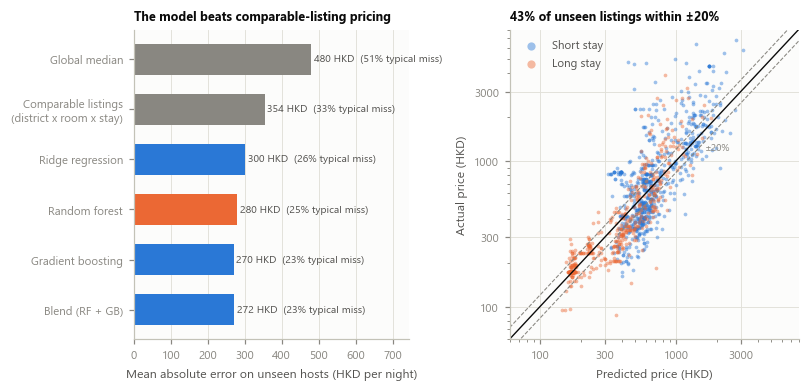

In [14]:
# ---- figure 4: how much better than the host's current approach, and what does a prediction look like? ----
order = ["Global median", "Comparable-listings baseline", "Ridge", "Random forest", "Gradient boosting", "Blend (RF + GB)"]
nice = {"Global median": "Global median", "Comparable-listings baseline": "Comparable listings\n(district x room x stay)", "Ridge": "Ridge regression",
        "Random forest": "Random forest", "Gradient boosting": "Gradient boosting", "Blend (RF + GB)": "Blend (RF + GB)"}
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.6), gridspec_kw=dict(width_ratios=[1, 1.05]))
a = ax[0]
vals = [res.loc[o, "MAE"] for o in order]
cols = [PAL["muted"] if o in ("Global median", "Comparable-listings baseline") else PAL["blue"] for o in order]
cols = [PAL["orange"] if o == BEST else c for o, c in zip(order, cols)]
a.barh([nice[o] for o in order][::-1], vals[::-1], color=cols[::-1], height=0.62)
for i, (o, v) in enumerate(zip(order[::-1], vals[::-1])):
    a.text(v + 8, i, f"{v:,.0f} HKD  ({pct(res.loc[o,'MedAPE'])} typical miss)", va="center", fontsize=6.8)
a.set_xlim(0, max(vals) * 1.55); a.set_xlabel("Mean absolute error on unseen hosts (HKD per night)"); a.grid(axis="y", visible=False)
a.set_title("The model beats comparable-listing pricing", fontsize=8.2)
b = ax[1]
mreg = Xte.long_stay.values == 1
for flag, col, lab in [(False, PAL["blue"], "Short stay"), (True, PAL["orange"], "Long stay")]:
    m = mreg == flag
    b.scatter(preds[BEST][m], pte[m], s=6, alpha=0.45, color=col, linewidths=0, label=lab)
lim = np.array([60, 8000])
b.plot(lim, lim, color=PAL["ink"], lw=0.9); b.plot(lim, lim * 1.2, color=PAL["muted"], lw=0.7, ls="--"); b.plot(lim, lim / 1.2, color=PAL["muted"], lw=0.7, ls="--")
b.set_xscale("log"); b.set_yscale("log"); b.set_xlim(lim); b.set_ylim(lim)
b.set_xticks([100, 300, 1000, 3000]); b.set_yticks([100, 300, 1000, 3000])
b.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter()); b.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
b.set_xlabel("Predicted price (HKD)"); b.set_ylabel("Actual price (HKD)")
b.legend(loc="upper left", markerscale=2.2); b.text(2500, 2000 / 1.25 * 0.74, "±20%", fontsize=6.5, color=PAL["muted"], ha="right")
b.set_title(f"{pct(res.loc[BEST,'Within20'])} of unseen listings within ±20%", fontsize=8.2)
fig.tight_layout(w_pad=1.2)
savefig("fig4_model_performance", fig)

## 10. Which factor families earn their place? (ablation study)

A host or a manager does not want a black box; they want to know **where the predictive value comes from**, and a data team
needs to know which data is worth collecting. We therefore rebuild the model **adding one family at a time** (same algorithm
and tuned hyper-parameters) and watch how the typical pricing error falls.

*Design decision:* differences between neighbouring steps are small (often 1-2 points), so a single 5-fold split is too noisy to
rank them – fold-to-fold variation is larger than the effect. We therefore use **3 repetitions of host-grouped 5-fold
cross-validation with different random host assignments**, pool the out-of-fold predictions of all 5,555 listings in each
repetition, and report the mean and the spread across repetitions. (This is a diagnostic of *information value*; it is not used to
select models, so using all listings does not contaminate the test result.) The two experience families (orange) are only
available once a listing has guests.

ablation took 61s


,step,kind,MedAPE,MedAPE_sd,MAE,Within20,gain_pts,gain_sd
0,Comparable-listings baseline,baseline,0.287,0.001,340.891,0.388,NaN,NaN
1,Property & capacity,launch,0.371,0.015,319.730,0.255,-8.321,1.575
2,+ Stay policy & quote,launch,0.245,0.003,285.723,0.418,12.522,1.279
3,+ Location,launch,0.240,0.008,269.880,0.436,0.531,0.768
4,+ Transit & centrality,launch,0.244,0.007,272.216,0.425,-0.407,0.186
5,+ Local competition,launch,0.240,0.007,271.379,0.430,0.385,0.092
6,+ Amenities,launch,0.225,0.005,257.322,0.457,1.540,0.589
7,+ Host profile,launch,0.226,0.003,258.629,0.455,-0.116,0.294
8,+ Listing text,launch,0.224,0.001,259.004,0.459,0.150,0.223
9,+ Reviews & ratings,experience,0.220,0.003,255.375,0.465,0.465,0.238


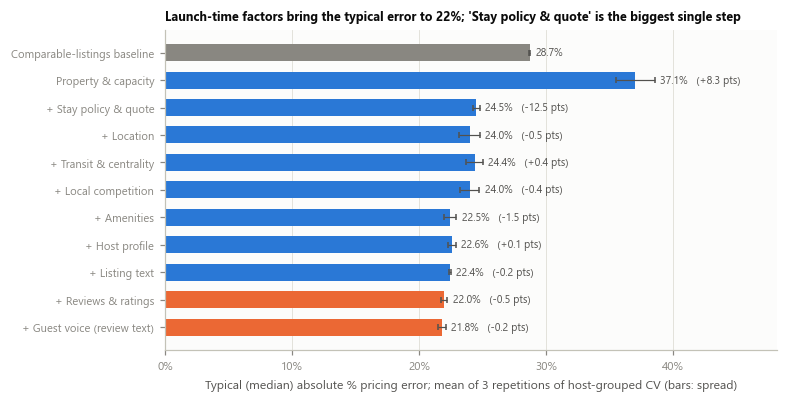

In [15]:
XX = pd.concat([X_all, EXP_ALL], axis=1)          # launch-time + experience factors
gb_model = tuned["Gradient boosting"].named_steps["model"]
STEPS = list(FAMILIES) + list(EXP_FAMILIES)
SEEDS = [11, 22, 33]
p_all = df.price_hkd.values

def pooled_oof(cols, seed):
    cvr = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
    o = cross_val_predict(make_pipe(cols, clone(gb_model)), XX, y, cv=cvr, groups=groups, n_jobs=-1)
    return metrics(p_all, np.exp(o))

def pooled_baseline(seed):
    cvr = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
    o = np.zeros(len(df))
    for a_, b_ in cvr.split(X_all, y, groups=groups):
        o[b_] = CompsBaseline().fit(X_all.iloc[a_], p_all[a_]).predict(X_all.iloc[b_])
    return metrics(p_all, o)

t0 = time.time()
runs = {"Comparable-listings baseline": [pooled_baseline(sd) for sd in SEEDS]}
cols_acc = []
for fam in STEPS:
    cols_acc = cols_acc + (FAMILIES[fam] if fam in FAMILIES else EXP_FAMILIES[fam])
    runs[fam] = [pooled_oof(list(cols_acc), sd) for sd in SEEDS]
print(f"ablation took {time.time()-t0:.0f}s")

names = list(runs)
rows = []
for i, nm in enumerate(names):
    med = np.array([r["MedAPE"] for r in runs[nm]])
    prev = np.array([r["MedAPE"] for r in runs[names[i - 1]]]) if i > 0 else None
    rows.append(dict(step=nm if i < 2 else "+ " + nm, kind="baseline" if i == 0 else ("launch" if nm in FAMILIES else "experience"),
                     MedAPE=med.mean(), MedAPE_sd=med.std(), MAE=np.mean([r["MAE"] for r in runs[nm]]),
                     Within20=np.mean([r["Within20"] for r in runs[nm]]),
                     gain_pts=(prev - med).mean() * 100 if prev is not None else np.nan,
                     gain_sd=(prev - med).std() * 100 if prev is not None else np.nan))
abl = pd.DataFrame(rows)
display(abl.round(3))

fig, ax = plt.subplots(figsize=(7.2, 3.7))
yy = np.arange(len(abl))[::-1]
colors = [PAL["muted"] if k == "baseline" else (PAL["blue"] if k == "launch" else PAL["orange"]) for k in abl.kind]
ax.barh(yy, abl.MedAPE, xerr=abl.MedAPE_sd, color=colors, height=0.62, error_kw=dict(ecolor=PAL["ink2"], lw=0.8, capsize=2))
ax.set_yticks(yy); ax.set_yticklabels(abl.step, fontsize=7.4)
for yi, v, sd, g_, k in zip(yy, abl.MedAPE, abl.MedAPE_sd, abl.gain_pts, abl.kind):
    txt = f"{v*100:.1f}%" + ("" if k == "baseline" or pd.isna(g_) else f"   ({-g_:+.1f} pts)")
    ax.text(v + sd + 0.004, yi, txt, va="center", fontsize=6.9)
ax.set_xlim(0, abl.MedAPE.max() * 1.3); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Typical (median) absolute % pricing error; mean of 3 repetitions of host-grouped CV (bars: spread)")
ax.grid(axis="y", visible=False)
launch = abl[abl.kind == "launch"]
big = launch.iloc[1:].gain_pts.idxmax()
ax.set_title(f"Launch-time factors bring the typical error to {launch.MedAPE.iloc[-1]*100:.0f}%; "
             f"'{launch.loc[big, 'step'].replace('+ ', '')}' is the biggest single step", fontsize=8.2, loc="left")
fig.tight_layout()
savefig("fig5_ablation", fig)
RESULTS["ablation"] = abl.to_dict(orient="records")

## 11. Final benchmark: refit, interpret, and size the uncertainty

### 11.1 How much does each family matter? (grouped permutation importance on unseen hosts)
For each family we scramble *all* its columns at once on the test set and measure how much the error grows. A family that
is correlated with others can look small in the ablation (others already carry the signal) but still matter when removed;
looking at both views protects us from over-interpreting either one.

In [16]:
best_pipe = tuned[BEST]
base_err = np.mean(np.abs(best_pipe.predict(Xte) - yte))
rng = np.random.default_rng(RANDOM_STATE)
imp_rows = []
for fam, cols in FAMILIES.items():
    deltas = []
    for _ in range(15):
        Xp = Xte.copy()
        perm = rng.permutation(len(Xp))
        Xp[cols] = Xte[cols].values[perm]
        deltas.append(np.mean(np.abs(best_pipe.predict(Xp) - yte)) - base_err)
    imp_rows.append(dict(family=fam, delta=np.mean(deltas) * 100, sd=np.std(deltas) * 100))
imp = pd.DataFrame(imp_rows).sort_values("delta", ascending=False)
display(imp.round(2))
RESULTS["importance"] = dict(base_mae_log=float(base_err), table=imp.to_dict(orient="records"))

,family,delta,sd
0,Property & capacity,21.02,1.01
1,Stay policy & quote,17.41,0.63
5,Amenities,10.99,0.48
2,Location,1.87,0.23
3,Transit & centrality,1.32,0.21
7,Listing text,1.10,0.09
6,Host profile,0.42,0.07
4,Local competition,0.02,0.08


### 11.2 What is a feature worth? A hedonic (log-linear) regression
Tree ensembles predict well but do not give a clean "price of a feature". For *explanation* we fit an interpretable log-price
regression on all modelled listings with **standard errors clustered by host** (a host's listings are not independent). In a
log-linear model, a coefficient β means that a one-unit change is associated with a `exp(β) − 1` percentage change in price.
This is **association, not causation**: e.g. a host who installs a washer may also have a nicer flat.

amenities used in the hedonic model: ['Kitchen', 'Hot water', 'Hangers', 'Hair dryer', 'TV', 'Washer', 'Shampoo', 'Elevator', 'Iron', 'Essentials']
hedonic model: n = 5,555, R2 = 0.70 (log price), 1,175 host clusters


,premium,lo,hi,p
Monthly-stay policy (28+ nights),-37.43,-44.03,-30.06,0.00
Professional host (5+ listings),-17.92,-25.06,-10.10,0.00
Shared bathroom,-10.66,-19.55,-0.79,0.04
Host lives in Hong Kong,-10.54,-19.99,0.02,0.05
Amenity: Hangers,-3.35,-8.65,2.27,0.24
Amenity: Washer,-1.87,-6.14,2.59,0.40
Amenity: Shampoo,-1.06,-9.74,8.47,0.82
Amenity: Kitchen,-0.61,-7.99,7.35,0.88
+500 m from nearest MTR,-0.59,-2.50,1.36,0.55
Amenity: Elevator,-0.55,-6.32,5.58,0.86


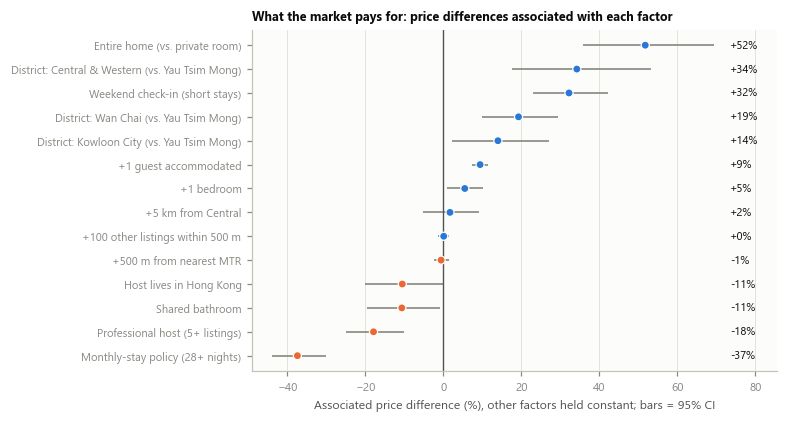

In [17]:
mid_am = [a for a in AMEN if 0.15 <= amen_prev[a] <= 0.85][:10]
print("amenities used in the hedonic model:", mid_am)
H = X_all.copy()
H["ly"] = y
for c in ["bedrooms", "baths", "beds"]:
    H[c] = H[c].fillna(H[c].median())
H["short_weekend"] = H.q_weekend * (1 - H.long_stay)
H["mtr_500m"] = H.dist_mtr_km * 2          # per +500 m
H["central_5km"] = H.dist_central_km / 5   # per +5 km
H["density_100"] = H.listings_500m / 100   # per +100 listings within 500 m
H["host_id"] = df.host_id
am_terms = " + ".join(f"Q('{AMEN_COLS[a]}')" for a in mid_am)
formula = ("ly ~ long_stay + short_weekend + C(room_type, Treatment('Private room')) + accommodates + bedrooms + baths + bath_shared"
           " + C(district_grp, Treatment('Yau Tsim Mong')) + mtr_500m + central_5km + density_100 + pro_host + host_local + " + am_terms)
ols = smf.ols(formula, data=H).fit(cov_type="cluster", cov_kwds={"groups": H.host_id})
print(f"hedonic model: n = {int(ols.nobs):,}, R2 = {ols.rsquared:.2f} (log price), {H.host_id.nunique():,} host clusters")

def prem(term):
    b, se = ols.params[term], ols.bse[term]
    return dict(premium=np.exp(b) - 1, lo=np.exp(b - 1.96 * se) - 1, hi=np.exp(b + 1.96 * se) - 1, p=ols.pvalues[term])

key = {
    "Monthly-stay policy (28+ nights)": "long_stay",
    "Weekend check-in (short stays)": "short_weekend",
    "Entire home (vs. private room)": "C(room_type, Treatment('Private room'))[T.Entire home/apt]",
    "+1 guest accommodated": "accommodates",
    "+1 bedroom": "bedrooms",
    "+1 bathroom": "baths",
    "Shared bathroom": "bath_shared",
    "+500 m from nearest MTR": "mtr_500m",
    "+5 km from Central": "central_5km",
    "+100 other listings within 500 m": "density_100",
    "Professional host (5+ listings)": "pro_host",
    "Host lives in Hong Kong": "host_local",
}
for dname in ["Central & Western", "Wan Chai", "Islands", "Kowloon City"]:
    t = f"C(district_grp, Treatment('Yau Tsim Mong'))[T.{dname}]"
    if t in ols.params.index: key[f"District: {dname} (vs. Yau Tsim Mong)"] = t
for a in mid_am:
    key[f"Amenity: {a}"] = f"Q('{AMEN_COLS[a]}')"
hed = pd.DataFrame({k: prem(v) for k, v in key.items()}).T.sort_values("premium")
display((hed * [100, 100, 100, 1]).round(2))
RESULTS["hedonic"] = dict(n=int(ols.nobs), r2=float(ols.rsquared), terms={k: {a: float(b) for a, b in r.items()} for k, r in hed.iterrows()},
                          amenities_used=mid_am)

# figure 6: forest plot of premiums
show = hed[~hed.index.str.startswith("Amenity")]          # amenity coefficients are controls (they proxy listing quality) - not shown
show = show[(show.p < 0.10) | show.index.isin(["+500 m from nearest MTR", "+5 km from Central", "+100 other listings within 500 m"])].copy()
fig, ax = plt.subplots(figsize=(7.2, 0.21 * len(show) + 0.95))
yy = np.arange(len(show))
cols_f = [PAL["blue"] if v >= 0 else PAL["orange"] for v in show.premium]
ax.hlines(yy, show.lo * 100, show.hi * 100, color=PAL["muted"], lw=1.1, zorder=2)
ax.scatter(show.premium * 100, yy, color=cols_f, s=28, zorder=3, edgecolor="white", linewidth=0.8)
ax.axvline(0, color=PAL["ink2"], lw=0.9)
ax.set_yticks(yy); ax.set_yticklabels(show.index, fontsize=7.3)
for yi, (v, hi_) in enumerate(zip(show.premium, show.hi)):
    ax.text(max(show.hi.max() * 100, 10) + 4, yi, f"{v*100:+.0f}%", va="center", fontsize=7.2, color=PAL["ink"])
ax.set_xlabel("Associated price difference (%), other factors held constant; bars = 95% CI"); ax.grid(axis="y", visible=False)
ax.set_xlim(show.lo.min() * 100 - 5, show.hi.max() * 100 + 16)
ax.set_title("What the market pays for: price differences associated with each factor", fontsize=8.2)
fig.tight_layout()
savefig("fig6_hedonic", fig)

## 12. From prediction to action: who is priced away from the benchmark, and does it cost them guests?

A prediction is only useful if it changes a decision. We use the benchmark as a **price audit**:
1. For *every* listing we obtain an **out-of-fold prediction** – the price a model that has never seen that host would have
   suggested (host-grouped 5-fold cross-validation, so a listing is never predicted by a model trained on its own host).
2. The **price gap** = actual price ÷ benchmark − 1. We call a listing *above benchmark* if it is priced ≥ 25% above, *below
   benchmark* if ≥ 20% below (the same ±25% band on a ratio scale), and *in line* otherwise.
3. We then ask the question a host really cares about: **do listings priced above the benchmark attract fewer guests?**
   Guests cannot be observed directly, so we use the number of reviews in the last 12 months (`number_of_reviews_ltm`)
   as a demand proxy (reviews are a roughly constant fraction of stays).

In [18]:
oof = cross_val_predict(clone(tuned[BEST]), X_all, y, cv=GroupKFold(n_splits=5), groups=groups, n_jobs=-1)
p_all = df.price_hkd.values
m_oof = metrics(p_all, np.exp(oof))
# comparable-listings baseline, same folds
oof_base = np.zeros(len(df))
for a_, b_ in GroupKFold(n_splits=5).split(X_all, y, groups=groups):
    oof_base[b_] = CompsBaseline().fit(X_all.iloc[a_], p_all[a_]).predict(X_all.iloc[b_])
m_base = metrics(p_all, oof_base)
print(f"All {len(df):,} listings, host-grouped 5-fold CV ->  {BEST}: MAE {m_oof['MAE']:.0f} HKD, median % error {pct(m_oof['MedAPE'],1)}, within +-20%: {pct(m_oof['Within20'])}, R2(log) {m_oof['R2_log']:.2f}")
print(f"                                  Comparable-listings baseline: MAE {m_base['MAE']:.0f} HKD, median % error {pct(m_base['MedAPE'],1)}, within +-20%: {pct(m_base['Within20'])}")
RESULTS["oof"] = dict(model=m_oof, baseline=m_base, mae_reduction=float(1 - m_oof["MAE"] / m_base["MAE"]))

df["pred"] = np.exp(oof)
df["gap"] = df.price_hkd / df.pred - 1
TH_HI, TH_LO = 0.25, 1 / 1.25 - 1
df["position"] = np.select([df.gap >= TH_HI, df.gap <= TH_LO], ["Above benchmark", "Below benchmark"], "In line")
pos_share = df.position.value_counts(normalize=True)
display(pos_share.round(3))
print("Median gap by regime / room type (should be ~0 if the benchmark is unbiased):")
display(df.groupby(["regime", "room_type"]).gap.agg(["size", "median"]).round(3).query("size >= 20"))
df[["id", "price_hkd", "pred", "gap", "position", "segment", "regime", "neighbourhood_cleansed", "room_type"]].round(3).to_csv(OUT / "listing_price_audit.csv", index=False)

# --- demand test --------------------------------------------------------------------------------------------------------
elig = df[(df.first_review <= SCRAPE_DATE - pd.Timedelta(days=365)) & df.review_scores_rating.notna()].copy()
elig["log_gap"] = np.log(elig.price_hkd / elig.pred)
elig["host_id"] = elig.host_id.astype(int)
elig["acc_log"] = np.log(elig.accommodates)
print(f"Demand test sample: {len(elig):,} listings with at least a full year of history (first review > 12 months before the scrape)")
f0 = "number_of_reviews_ltm ~ log_gap + C(regime) + C(room_type) + C(neighbourhood_cleansed) + acc_log"
f1 = f0 + " + review_scores_rating"
glm = {}
for nm, f in [("controls", f0), ("controls + rating", f1)]:
    glm[nm] = smf.glm(f, data=elig, family=sm.families.Poisson()).fit(cov_type="cluster", cov_kwds={"groups": elig.host_id})
irr = {}
for nm, mdl in glm.items():
    b, se = mdl.params["log_gap"], mdl.bse["log_gap"]
    k = np.log(1.10)    # +10% price relative to benchmark
    irr[nm] = dict(irr_10=float(np.exp(b * k)), lo=float(np.exp((b - 1.96 * se) * k)), hi=float(np.exp((b + 1.96 * se) * k)), p=float(mdl.pvalues["log_gap"]))
    print(f"{nm:18s}: +10% above benchmark -> reviews x{irr[nm]['irr_10']:.3f}  (95% CI {irr[nm]['lo']:.3f}-{irr[nm]['hi']:.3f}), p = {irr[nm]['p']:.3g}")
# robustness: Inside Airbnb's own occupancy estimate, OLS on log(1+occupancy nights)
elig["lo"] = np.log1p(elig.estimated_occupancy_l365d)
ols_occ = smf.ols("lo ~ log_gap + C(regime) + C(room_type) + C(neighbourhood_cleansed) + acc_log + review_scores_rating", data=elig).fit(cov_type="cluster", cov_kwds={"groups": elig.host_id})
print(f"robustness (estimated occupancy nights, log): +10% above benchmark -> {100*(np.exp(ols_occ.params['log_gap']*np.log(1.1))-1):+.1f}%  (p = {ols_occ.pvalues['log_gap']:.3g})")
RESULTS["demand"] = dict(n=len(elig), irr=irr, occupancy_effect_10pct=float(np.exp(ols_occ.params["log_gap"] * np.log(1.1)) - 1),
                         occupancy_p=float(ols_occ.pvalues["log_gap"]))

All 5,555 listings, host-grouped 5-fold CV ->  Random forest: MAE 258 HKD, median % error 21.0%, within +-20%: 48%, R2(log) 0.76
                                  Comparable-listings baseline: MAE 335 HKD, median % error 28.6%, within +-20%: 39%


position
In line            0.525
Below benchmark    0.268
Above benchmark    0.207
Name: proportion, dtype: float64

Median gap by regime / room type (should be ~0 if the benchmark is unbiased):


size  median
regime                  room_type                    
Long stay (28+ nights)  Entire home/apt   591  -0.052
                        Private room     1752  -0.034
                        Shared room        21  -0.374
Short stay (<28 nights) Entire home/apt  1351  -0.041
                        Private room     1753  -0.056
                        Shared room        73  -0.395

Demand test sample: 2,412 listings with at least a full year of history (first review > 12 months before the scrape)


controls          : +10% above benchmark -> reviews x0.941  (95% CI 0.913-0.969), p = 6.45e-05
controls + rating : +10% above benchmark -> reviews x0.931  (95% CI 0.909-0.953), p = 3.23e-09
robustness (estimated occupancy nights, log): +10% above benchmark -> -8.3%  (p = 4e-07)


,gap_med,rev_mean,rev_med,n
gap_q,,,,
0,-0.42,10.13,2.0,483
1,-0.23,11.50,3.0,482
2,-0.07,9.70,3.0,482
3,0.13,8.34,2.0,482
4,0.65,5.10,1.0,483


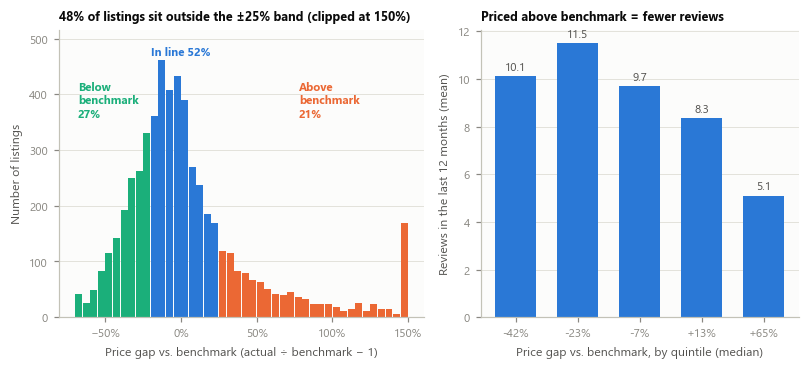

In [19]:
elig["gap_q"] = pd.qcut(elig.log_gap, 5, labels=False)
qt = elig.groupby("gap_q").agg(gap_med=("gap", "median"), rev_mean=("number_of_reviews_ltm", "mean"), rev_med=("number_of_reviews_ltm", "median"), n=("gap", "size"))
display(qt.round(2))

fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.4), gridspec_kw=dict(width_ratios=[1.15, 1]))
a = ax[0]
g_ = np.clip(df.gap.values, -0.7, 1.5)
bins_ = np.linspace(-0.7, 1.5, 45)
cnt, edges_ = np.histogram(g_, bins=bins_)
centers = (edges_[:-1] + edges_[1:]) / 2
colr = [PAL["orange"] if c >= TH_HI else (PAL["aqua"] if c <= TH_LO else PAL["blue"]) for c in centers]
a.bar(centers, cnt, width=(edges_[1] - edges_[0]) * 0.92, color=colr)
a.set_xlabel("Price gap vs. benchmark (actual ÷ benchmark − 1)"); a.set_ylabel("Number of listings")
a.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
a.text(0.78, cnt.max() * 0.92, f"Above\nbenchmark\n{pct(pos_share.get('Above benchmark',0))}", color=PAL["orange"], fontsize=7.5, fontweight="bold", va="top")
a.text(-0.68, cnt.max() * 0.92, f"Below\nbenchmark\n{pct(pos_share.get('Below benchmark',0))}", color=PAL["aqua"], fontsize=7.5, fontweight="bold", va="top")
a.text(0.0, cnt.max() * 1.02, f"In line {pct(pos_share.get('In line',0))}", color=PAL["blue"], fontsize=7.5, fontweight="bold", ha="center")
a.set_ylim(0, cnt.max() * 1.12); a.grid(axis="x", visible=False)
a.set_title(f"{pct(1 - pos_share.get('In line', 0))} of listings sit outside the ±25% band (clipped at 150%)", fontsize=8.2)
b = ax[1]
labs = [f"{v*100:+.0f}%" for v in qt.gap_med]
b.bar(range(5), qt.rev_mean, color=PAL["blue"], width=0.66)
for i, (v, n) in enumerate(zip(qt.rev_mean, qt.n)):
    b.text(i, v + 0.25, f"{v:.1f}", ha="center", fontsize=7.5)
b.set_xticks(range(5)); b.set_xticklabels(labs); b.grid(axis="x", visible=False)
b.set_xlabel("Price gap vs. benchmark, by quintile (median)"); b.set_ylabel("Reviews in the last 12 months (mean)")
b.set_title("Priced above benchmark = fewer reviews", fontsize=8.2)
fig.tight_layout(w_pad=1.2)
savefig("fig7_price_gap_demand", fig)
RESULTS["gap"] = dict(shares={k: float(v) for k, v in pos_share.items()}, thresholds=[TH_LO, TH_HI],
                      quintiles=qt.reset_index().to_dict(orient="records"))

## 13. Existing listings: what do reputation and guest feedback add?

The launch-time benchmark answers *"what should a new listing charge?"*. Operators with live listings ask a second question:
*"given my ratings and reviews, is my price justified?"* We therefore fit a second model that **adds the experience families**
(ratings, review activity, guest-voice text features) to the launch-time factors, using the same split and hyper-parameters,
and compare it with the launch-time model on the test hosts that have reviews.

We then look at the **guest voice**: what do guests of listings priced *above* vs. *below* benchmark talk about? This links
the quantitative price audit with qualitative feedback.

In [20]:
rated_te = XX.iloc[te].rs_rating.notna().values
mdl_exp = make_pipe(NEW_COLS + EXP_COLS, clone(gb_model)).fit(XX.iloc[tr], ytr)
mdl_new = make_pipe(NEW_COLS, clone(gb_model)).fit(XX.iloc[tr], ytr)
m_new_all, m_exp_all = metrics(pte, np.exp(mdl_new.predict(XX.iloc[te]))), metrics(pte, np.exp(mdl_exp.predict(XX.iloc[te])))
m_new_r = metrics(pte[rated_te], np.exp(mdl_new.predict(XX.iloc[te][rated_te])))
m_exp_r = metrics(pte[rated_te], np.exp(mdl_exp.predict(XX.iloc[te][rated_te])))
cmp_exp = pd.DataFrame({"Launch-time model (all test)": m_new_all, "+ experience (all test)": m_exp_all,
                        f"Launch-time model (rated, n={rated_te.sum()})": m_new_r, "+ experience (rated)": m_exp_r}).T
display(cmp_exp[["MAE", "MedAPE", "Within20", "R2_log"]].round(3))
RESULTS["existing_model"] = {k: {a: float(b) for a, b in r.items()} for k, r in cmp_exp.iterrows()}

,MAE,MedAPE,Within20,R2_log
Launch-time model (all test),269.814,0.228,0.441,0.732
+ experience (all test),263.806,0.228,0.446,0.749
"Launch-time model (rated, n=623)",277.807,0.266,0.396,0.667
+ experience (rated),270.475,0.248,0.398,0.690


In [21]:
# --- guest voice by price position ---
gv = df[["position", "regime"] + []].join(EXP_ALL[GV_COLS]).dropna(subset=["gv_sentiment"])
topic_names = {"gv_location": "Mentions location / transit", "gv_clean": "Praises cleanliness", "gv_dirty": "Complains of dirt / smell / bugs",
               "gv_noise": "Mentions noise", "gv_small": "Says small / cramped", "gv_value": "Says good value",
               "gv_pricey": "Says expensive / overpriced", "gv_host": "Praises host service"}
tab = gv.groupby("position")[list(topic_names)].mean().T.rename(index=topic_names)
tab["sentiment"] = np.nan
tab.loc["Average review sentiment (VADER, -1..+1)"] = gv.groupby("position").gv_sentiment.mean()
tab = tab.drop(columns="sentiment")
cols_order = [c for c in ["Below benchmark", "In line", "Above benchmark"] if c in tab.columns]
tab = tab[cols_order]
display((tab * 100).round(1).rename(columns={c: f"{c} (n={int((gv.position==c).sum())})" for c in cols_order}))
# significance of above vs below for each topic (Mann-Whitney) - exploratory, so we also report how many tests were run
from scipy.stats import mannwhitneyu
sig = {}
for c in list(topic_names) + ["gv_sentiment"]:
    a_ = gv.loc[gv.position == "Above benchmark", c]; b_ = gv.loc[gv.position == "Below benchmark", c]
    if len(a_) > 10 and len(b_) > 10:
        sig[c] = float(mannwhitneyu(a_, b_).pvalue)
print("Mann-Whitney p-values, above vs below benchmark (9 exploratory tests; Bonferroni threshold 0.0056):",
      {k: round(v, 4) for k, v in sig.items()})
RESULTS["guest_voice"] = dict(n=int(len(gv)), table={r: {c: float(v) for c, v in tab.loc[r].items()} for r in tab.index}, pvalues=sig)

position,Below benchmark (n=686),In line (n=887),Above benchmark (n=417)
Mentions location / transit,57.7,61.8,62.1
Praises cleanliness,32.0,31.3,31.4
Complains of dirt / smell / bugs,5.4,4.7,3.7
Mentions noise,4.2,4.3,3.7
Says small / cramped,15.5,13.7,11.6
Says good value,9.7,8.0,6.9
Says expensive / overpriced,1.3,1.2,1.6
Praises host service,33.3,34.5,37.0
"Average review sentiment (VADER, -1..+1)",67.9,69.7,72.3


Mann-Whitney p-values, above vs below benchmark (9 exploratory tests; Bonferroni threshold 0.0056): {'gv_location': 0.0002, 'gv_clean': 0.8727, 'gv_dirty': 0.0004, 'gv_noise': 0.0479, 'gv_small': 0.0, 'gv_value': 0.0, 'gv_pricey': 0.6815, 'gv_host': 0.001, 'gv_sentiment': 0.0001}


**Business reading.** Only a minority of listings can be analysed this way (English reviews, ≥ 3 of them), so these results
are *exploratory* – we apply a Bonferroni correction because we look at nine topics at once. Where a difference survives that
correction it is a lead for the host (e.g. "overpriced" complaints), not proof.

## 14. The decision tool: a price benchmark with a plausible band

A single number invites false precision. Hosts need **a recommended price and a band** inside which the market would not be
surprised. We estimate the band from the model's own out-of-fold errors (the 10th–90th percentile of the log error, computed
separately for short and long stays because errors differ), and **check its coverage on the held-out test hosts** – a band
labelled "80%" must contain about 80% of unseen listings, otherwise it is misleading.

In [22]:
# band from OUT-OF-FOLD residuals on the TRAINING hosts only, then tested on the held-out test hosts
oof_tr = cross_val_predict(clone(tuned[BEST]), Xtr, ytr, cv=GroupKFold(n_splits=5), groups=gtr, n_jobs=-1)
res_tr = ytr - oof_tr
Q_BAND = {int(r): np.percentile(res_tr[Xtr.long_stay.values == r], [10, 90]) for r in (0, 1)}
pred_te_log = tuned[BEST].predict(Xte)
lo_te = pred_te_log + np.array([Q_BAND[int(r)][0] for r in Xte.long_stay.values])
hi_te = pred_te_log + np.array([Q_BAND[int(r)][1] for r in Xte.long_stay.values])
cov = float(np.mean((yte >= lo_te) & (yte <= hi_te)))
cov_by = {("long" if r else "short"): float(np.mean(((yte >= lo_te) & (yte <= hi_te))[Xte.long_stay.values == r])) for r in (0, 1)}
print(f"Nominal 80% band covers {pct(cov)} of unseen listings (short stay {pct(cov_by['short'])}, long stay {pct(cov_by['long'])}); "
      f"median band width: x{np.exp(np.median(hi_te - lo_te)):.2f} (e.g. 500 HKD -> {500*np.exp(np.median(Q_BAND[0][0])):.0f}-{500*np.exp(np.median(Q_BAND[0][1])):.0f} HKD for short stays)")
RESULTS["band"] = dict(coverage=cov, coverage_by=cov_by, q_short=[float(v) for v in Q_BAND[0]], q_long=[float(v) for v in Q_BAND[1]])

# final model for the tool: refit on ALL modelled listings; band from all-data out-of-fold residuals
FINAL = clone(tuned[BEST]).fit(X_all, y)
res_all = y - oof
Q_ALL = {int(r): np.percentile(res_all[X_all.long_stay.values == r], [10, 90]) for r in (0, 1)}

Nominal 80% band covers 79% of unseen listings (short stay 79%, long stay 79%); median band width: x3.34 (e.g. 500 HKD -> 281-937 HKD for short stays)


In [23]:
TYPICAL = {c: X_all[c].median() for c in NEW_COLS if c not in CAT_COLS}
for c in CAT_COLS: TYPICAL[c] = X_all[c].mode()[0]
UNFLAGGED_AMEN = float(np.median(X_all.n_amenities - X_all[list(AMEN_COLS.values())].sum(axis=1)))
BASIC_KIT = ["Wifi", "Air conditioning", "Hot water", "Kitchen", "TV"]

def make_row(district, room_type, property_type, accommodates, bedrooms, baths, lat, lon, long_stay=0, weekend=0,
             amenities=BASIC_KIT, shared_bath=0, min_nights=None, pro_host=0, host_local=1):
    """Builds ONE listing from plain business inputs. Everything not specified takes the market-typical value."""
    r = dict(TYPICAL)
    g = geo_features([lat], [lon]).iloc[0]
    r.update(room_type=room_type, property_type_grp=property_type if property_type in TOP_PTYPES else "Other", accommodates=accommodates,
             bedrooms=bedrooms, studio=int(bedrooms == 0), beds=max(1, round(accommodates / 2)), baths=baths, bath_shared=shared_bath,
             long_stay=long_stay, district_grp=district if district in KEEP_DISTRICTS else "Other districts",
             region=REGION.get(district, "New Territories & Islands"), lat=lat, lon=lon,
             q_weekend=weekend if not long_stay else 0, pro_host=pro_host, host_local=host_local)
    mn = min_nights if min_nights else (30 if long_stay else 2)
    r.update(log_min_nights=np.log(mn), q_log_nights=np.log(mn))
    for c in ["dist_mtr_km", "n_mtr_1km", "dist_central_km", "dist_tst_km", "dist_hub_min_km"]:
        r[c] = float(g[c])
    pt = np.radians([[lat, lon]])
    r["listings_500m"] = int(list_tree.query_radius(pt, r=0.5 / EARTH_KM, count_only=True)[0])
    r["listings_1km"] = int(list_tree.query_radius(pt, r=1.0 / EARTH_KM, count_only=True)[0])
    for a, c in AMEN_COLS.items():
        r[c] = int(a in amenities)
    r["n_amenities"] = len(amenities) + UNFLAGGED_AMEN
    return pd.DataFrame([r])[NEW_COLS]

def benchmark(row_df, model=None):
    """Returns (benchmark price, low, high) in HKD."""
    model = model or FINAL
    lp = float(model.predict(row_df)[0]); ls = int(row_df.long_stay.iloc[0])
    return np.exp(lp), np.exp(lp + Q_ALL[ls][0]), np.exp(lp + Q_ALL[ls][1])

def station(name):
    return MTR.loc[MTR.name == name, ["lat", "lon"]].iloc[0].values + np.array([0.0012, 0.0010])   # ~150 m from the station

PROFILES = {
    "Wan Chai flat\n(1 bed, 2 guests)": dict(district="Wan Chai", room_type="Entire home/apt", property_type="Entire rental unit", accommodates=2,
                                           bedrooms=1, baths=1, lat=station("Wan Chai")[0], lon=station("Wan Chai")[1]),
    "Mong Kok room\n(shared bath)": dict(district="Yau Tsim Mong", room_type="Private room", property_type="Private room in rental unit", accommodates=2,
                                        bedrooms=1, baths=1, shared_bath=1, lat=station("Mong Kok")[0], lon=station("Mong Kok")[1]),
    "Sai Kung house\n(3 bed, 6 guests)": dict(district="Sai Kung", room_type="Entire home/apt", property_type="Entire home", accommodates=6,
                                             bedrooms=3, baths=2, lat=22.3815, lon=114.2700,
                                             amenities=BASIC_KIT + ["Washer", "Free parking on premises"]),
}
scen_rows = []
for nm, kw in PROFILES.items():
    for lab, extra in [("Short stay, weekday", dict(long_stay=0, weekend=0)), ("Short stay, weekend", dict(long_stay=0, weekend=1)),
                       ("Monthly stay", dict(long_stay=1, weekend=0))]:
        p_, lo_, hi_ = benchmark(make_row(**kw, **extra))
        scen_rows.append(dict(profile=nm.replace("\n", " "), profile_short=nm, stay=lab, price=p_, lo=lo_, hi=hi_))
scen = pd.DataFrame(scen_rows)
display(scen[["profile", "stay", "price", "lo", "hi"]].round(0))
RESULTS["scenarios"] = scen.drop(columns="profile_short").to_dict(orient="records")

,profile,stay,price,lo,hi
0,"Wan Chai flat (1 bed, 2 guests)","Short stay, weekday",1018.0,597.0,1842.0
1,"Wan Chai flat (1 bed, 2 guests)","Short stay, weekend",1079.0,633.0,1954.0
2,"Wan Chai flat (1 bed, 2 guests)",Monthly stay,438.0,310.0,602.0
3,Mong Kok room (shared bath),"Short stay, weekday",407.0,239.0,737.0
4,Mong Kok room (shared bath),"Short stay, weekend",456.0,268.0,826.0
5,Mong Kok room (shared bath),Monthly stay,207.0,147.0,285.0
6,"Sai Kung house (3 bed, 6 guests)","Short stay, weekday",2503.0,1467.0,4531.0
7,"Sai Kung house (3 bed, 6 guests)","Short stay, weekend",2574.0,1509.0,4661.0
8,"Sai Kung house (3 bed, 6 guests)",Monthly stay,1925.0,1363.0,2643.0


**Why not rank amenities by "model-implied uplift"?** We tried it and rejected it: when a flag such as *hair dryer* is switched on
for budget rooms that lack it, the model treats the room as a different kind of (hotel-like, professionally managed) listing and
returns implausibly large jumps. Amenities are *markers* of listing type rather than priced upgrades, and the ablation confirms they add
only a little accuracy once type, stay and district are known. Instead we show levers a host really controls, on one realistic profile.

,lever,price,change
0,Accept monthly stays (28+ nights),438.104,-0.569
6,Add self check-in,1039.182,0.021
5,Add washer,1055.614,0.037
4,Add dedicated workspace,1061.821,0.043
2,+1 guest accommodated (sofa bed),1072.197,0.054
1,Weekend check-in (vs. weekday),1079.012,0.060
3,+1 bedroom (sleeps 4),1380.319,0.356


base: Wan Chai flat, short weekday stay = 1,018 HKD


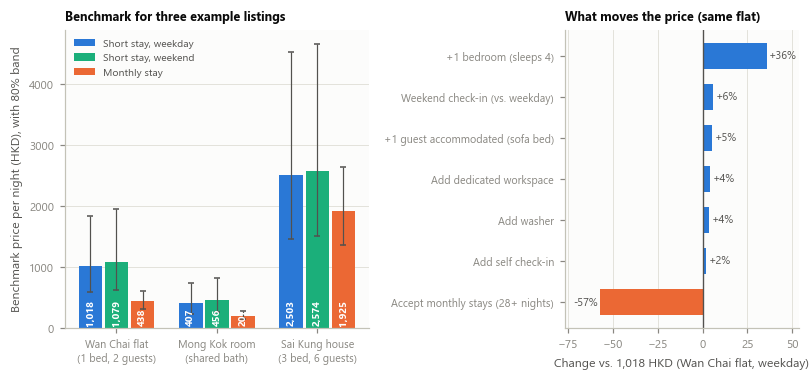

In [24]:
base_kw = {**PROFILES[list(PROFILES)[0]], "long_stay": 0, "weekend": 0}
def bench(**ov):
    return benchmark(make_row(**{**base_kw, **ov}))[0]
p0 = bench()
LEVERS = {
    "Accept monthly stays (28+ nights)": dict(long_stay=1),
    "Weekend check-in (vs. weekday)": dict(weekend=1),
    "+1 guest accommodated (sofa bed)": dict(accommodates=3),
    "+1 bedroom (sleeps 4)": dict(bedrooms=2, accommodates=4),
    "Add dedicated workspace": dict(amenities=BASIC_KIT + ["Dedicated workspace"]),
    "Add washer": dict(amenities=BASIC_KIT + ["Washer"]),
    "Add self check-in": dict(amenities=BASIC_KIT + ["Self check-in"]),
}
lev = pd.DataFrame([dict(lever=k, price=bench(**v), change=bench(**v) / p0 - 1) for k, v in LEVERS.items()]).sort_values("change")
display(lev.round(3))
print(f"base: Wan Chai flat, short weekday stay = {p0:,.0f} HKD")

fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.5), gridspec_kw=dict(width_ratios=[1.3, 1]))
a = ax[0]
profs = list(PROFILES)
xs = np.arange(len(profs)); w = 0.26
for j, (stay, col) in enumerate([("Short stay, weekday", PAL["blue"]), ("Short stay, weekend", PAL["aqua"]), ("Monthly stay", PAL["orange"])]):
    sub = scen[scen.stay == stay].set_index("profile_short").loc[profs]
    a.bar(xs + (j - 1) * w, sub.price, w * 0.9, color=col, label=stay,
          yerr=[sub.price - sub.lo, sub.hi - sub.price], error_kw=dict(ecolor=PAL["ink2"], lw=0.8, capsize=1.8))
    for xi, v in zip(xs + (j - 1) * w, sub.price):
        a.text(xi, 40, f"{v:,.0f}", ha="center", va="bottom", fontsize=6.6, color="white", fontweight="bold", rotation=90)
a.set_xticks(xs); a.set_xticklabels(profs, fontsize=7); a.set_ylabel("Benchmark price per night (HKD), with 80% band")
a.legend(loc="upper left", fontsize=6.8); a.grid(axis="x", visible=False)
a.set_title("Benchmark for three example listings", fontsize=8.2)
b = ax[1]
yy = np.arange(len(lev))
b.barh(yy, lev.change * 100, color=[PAL["blue"] if v >= 0 else PAL["orange"] for v in lev.change], height=0.62)
b.set_yticks(yy); b.set_yticklabels(lev.lever, fontsize=7)
for yi, v in zip(yy, lev.change):
    b.text(v * 100 + (1.2 if v >= 0 else -1.2), yi, f"{v*100:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=7)
b.axvline(0, color=PAL["ink2"], lw=0.9); b.set_xlim(lev.change.min() * 100 * 1.35, max(lev.change.max() * 100 * 1.5, 12))
b.set_xlabel(f"Change vs. {p0:,.0f} HKD (Wan Chai flat, weekday)"); b.grid(axis="y", visible=False)
b.set_title("What moves the price (same flat)", fontsize=8.2)
fig.tight_layout(w_pad=1.2)
savefig("fig8_decision_tool", fig)
RESULTS["levers"] = dict(base_price=float(p0), items=lev.to_dict(orient="records"))

**How much should we trust a single lever?** Individual effects depend on the model and the profile, so we cross-check the two levers
that matter most commercially – *weekend check-in* and *one more guest* – with the average effect over **all short-stay listings**
under each of the three tuned models (and compare with the hedonic regression of section 11.2). We treat the levers as direction and
order of magnitude, not as exact returns.

In [25]:
sh_ = X_all.long_stay == 0
chk = {}
for nm in ML_NAMES:
    m_ = tuned[nm]
    A, B = X_all[sh_].copy(), X_all[sh_].copy(); B["q_weekend"] = 1; A["q_weekend"] = 0
    wk = float(np.exp((m_.predict(B) - m_.predict(A)).mean()) - 1)
    A, B = X_all[sh_].copy(), X_all[sh_].copy(); B["accommodates"] = A.accommodates + 1
    gu = float(np.exp((m_.predict(B) - m_.predict(A)).mean()) - 1)
    chk[nm] = dict(weekend=wk, plus_one_guest=gu)
chk["Hedonic regression"] = dict(weekend=float(RESULTS["hedonic"]["terms"]["Weekend check-in (short stays)"]["premium"]),
                                 plus_one_guest=float(RESULTS["hedonic"]["terms"]["+1 guest accommodated"]["premium"]))
display((pd.DataFrame(chk).T * 100).round(1).rename(columns={"weekend": "Weekend check-in (%)", "plus_one_guest": "+1 guest (%)"}))
RESULTS["lever_check"] = chk
save_results()

,Weekend check-in (%),+1 guest (%)
Ridge,10.2,9.3
Random forest,13.1,7.7
Gradient boosting,18.2,10.4
Hedonic regression,32.2,9.4


## 15. Decision log, limitations and recommendations

### Decisions we made (and why)
| # | Decision | Business / statistical reason |
|---|---|---|
| 1 | Drop listings without a price (15% of the file) | Two thirds cannot be booked; a benchmark is about bookable listings. Risk: slight survivor bias |
| 2 | Remove prices < 50 HKD or above the 99.5th percentile | Data errors (a 0.73 HKD tent) and a few luxury outliers that dominate squared error; the tool targets typical hosts |
| 3 | Treat **stay length as a core factor** and a segmentation (≥ 28 nights) | The price is a quote for a specific stay; monthly stays cost a fraction per night |
| 4 | Add **quote-context controls** (quoted nights, weekend check-in) but **not lead time** | They are properties of the scraped quote that move price; lead time partly reflects demand (leakage) |
| 5 | Model `log(price)` | Percentage errors, tamed skewness |
| 6 | Split and cross-validate **by host**; pick the most representative host split by composition only | Prevents memorising professional hosts; avoids an unbalanced test set |
| 7 | All preprocessing inside a `Pipeline`; test set used once; models selected by CV | No leakage, honest estimate |
| 8 | Compare with the **comparable-listings baseline** that hosts use today | The business question is "better than what I do now?" |
| 8b | Keep only two binary host flags (professional, local) | Continuous host-history variables let trees memorise professional hosts and did not help on unseen hosts (22.8% vs 22.2% typical error) |
| 9 | Launch-time model excludes ratings, reviews, superhost | A new host does not have them; they are used in a separate model for existing listings |
| 10 | Distances from OpenStreetMap, only HK heavy-rail MTR | Reproducible, cached, Shenzhen/Light Rail removed |
| 11 | Interpret with a hedonic regression, clustered by host, and call results *associations* | Observational data; no causal claims |
| 12 | Segment markets with KMeans **without price** as an input, k chosen by silhouette with a minimum segment size | Price differences between segments are findings, and segments are big enough to matter |
| 13 | Report a band, and verify its coverage on unseen hosts | Avoids false precision |

### Limitations (also in the report)
* The price is **an asking price quoted for one stay**, not a transaction price or revenue; seasonality beyond weekend/weekday is not modelled.
* Listings without a price (mostly not bookable) are excluded; luxury listings above the 99.5th percentile are out of scope.
* Demand is observed only through **reviews** (a proxy); the price-gap → demand result is an association and could be driven by
  unobserved quality (photos, view, floor).
* Licence status, which matters legally in Hong Kong, is empty in the data, so we cannot separate licensed from unlicensed supply.
* Straight-line distances ignore hills and walking routes; MTR data come from a volunteer-maintained map.
* Review text analysis is limited to English-like comments and keyword topics.
* Data are a single snapshot (25 Sep 2026); a production tool needs periodic retraining.

In [26]:
RESULTS["meta"] = dict(random_state=RANDOM_STATE, python_note="scikit-learn / statsmodels / matplotlib; see notebook header",
                       model_best=BEST, k_segments=K_SEG)
save_results()
print("Saved outputs/results.json and", len(list(FIG.glob('*.png'))), "figures in outputs/figures/")
print(pd.Series(RESULTS["models"]["table"]).apply(lambda r: f"MAE {r['MAE']:.0f}  MedAPE {r['MedAPE']:.1%}  within20 {r['Within20']:.0%}").to_string())

Saved outputs/results.json and 8 figures in outputs/figures/
Global median                   MAE 480  MedAPE 51.4%  within20 19%
Comparable-listings baseline    MAE 354  MedAPE 32.6%  within20 33%
Ridge                           MAE 300  MedAPE 26.0%  within20 40%
Random forest                   MAE 280  MedAPE 24.7%  within20 43%
Gradient boosting               MAE 270  MedAPE 22.8%  within20 44%
Blend (RF + GB)                 MAE 272  MedAPE 23.3%  within20 44%
